# 0. Setup


In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración para ver más filas y columnas
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

# Deshabilitar notación científica
pd.options.display.float_format = '{:.2f}'.format

def imprimir_tasa(tabla):
    # Las tasas se leen en porcentaje. El resto del notebook sigue en dos decimales.
    with pd.option_context('display.float_format', '{:.1%}'.format):
        print(tabla)


# 1. Entendimiento y preparación de los datos

En esta sección se revisan los datos tal como llega: tamaño, tipos, nulos y valores que no tienen sentido. Después se deja una versión limpia y se miran las distribuciones, sobre todo las que cambian la tasa de `churn`. La imputación de los nulos que sobrevivan a la limpieza no se hace aquí. La mediana tiene que salir solo del conjunto de entrenamiento, para no filtrar el test.


## 1.1. Carga y dimensiones


In [2]:
# Cargar datos
df = pd.read_csv("churn.csv")


In [3]:
# Explorar datos
df.head(n=15)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.00,France,Female,46.00,9,0.00,1,1,1,81014.50,1
1,689.00,Germany,Male,67.00,9,157094.78,1,1,1,99490.01,0
2,477.00,Spain,Female,48.00,2,129120.64,1,0,1,26475.79,0
3,573.00,Germany,Female,35.00,9,206868.78,2,0,1,102986.15,0
4,849.00,France,Male,69.00,7,71996.09,1,1,1,139065.94,0
5,796.00,France,Male,24.00,8,0.00,2,1,0,61349.37,0
6,497.00,Spain,Male,24.00,3,0.00,2,1,0,76390.01,0
7,675.00,France,Female,21.00,8,NaN,1,1,0,18203.00,0
8,636.00,Germany,Female,31.00,9,80844.69,2,1,1,74641.90,0
9,789.00,France,Female,NaN,8,66201.96,1,1,1,79458.12,0


In [4]:
# Dimensiones (filas, columnas)
df.shape


(10045, 11)

In [5]:
# Información de los datos
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 863.4 KB


In [6]:
# Estadísticas descriptivas
df.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,9795.00,9745.00,10045.00,9845.00,10045.00,10045.00,10045.00,9695.00,10045.00
mean,650.69,38.94,5.02,76317.50,1.53,0.70,0.51,100069.01,0.20
std,97.09,10.73,2.90,62422.43,0.58,0.46,0.50,57510.69,0.40
min,95.00,-1.00,-2.00,0.00,1.00,0.00,0.00,-5000.00,0.00
1%,432.00,21.00,0.00,0.00,1.00,0.00,0.00,1787.11,0.00
5%,490.00,25.00,1.00,0.00,1.00,0.00,0.00,9984.24,0.00
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51013.65,0.00
50%,652.00,37.00,5.00,97042.60,1.00,1.00,1.00,100130.95,0.00
75%,718.00,44.00,8.00,127559.97,2.00,1.00,1.00,149382.88,0.00
95%,813.00,60.00,9.00,162554.68,2.00,1.00,1.00,190170.51,1.00


El archivo trae **10,045 filas y 11 columnas**. Cada fila es un cliente. No existe un identificador, por lo que si hay dos filas iguales no hay forma de saber si son dos personas o la misma cargada dos veces.

`churn` es la etiqueta. Vale 1 si el cliente abandonó y 0 si se quedó. En crudo hay **2,045 abandonos (20.4%)**. El enunciado cita una tasa de deserción de la banca minorista cerca del **15%**. Esta muestra viene un poco más cargada de abandonos.


## 1.2. Tipos de variables

| Variable | Tipo | Qué representa | Rol |
|---|---|---|---|
| `credit_score` | numérica | puntaje crediticio | predictora |
| `country` | categórica | país del cliente | predictora |
| `gender` | categórica | sexo | predictora |
| `age` | numérica | edad en años | predictora |
| `tenure` | numérica discreta | años como cliente | predictora |
| `balance` | numérica | saldo de la cuenta | predictora |
| `products_number` | discreta (1 a 4) | cantidad de productos contratados | predictora |
| `credit_card` | binaria (0/1) | tiene tarjeta de crédito | predictora |
| `active_member` | binaria (0/1) | el cliente está activo | predictora |
| `estimated_salary` | numérica | salario estimado | predictora |
| `churn` | binaria (0/1) | abandonó | objetivo |

No hay fechas ni texto libre. `products_number` parece un conteo, pero la relación con el abandono no es lineal: se va a tratar como categoría cuando se arme el modelo. `credit_card` y `active_member` ya vienen en 0/1.


## 1.3. Calidad del registro


In [7]:
# Nulos por columna
nulos = df.isna().sum()
print(nulos)
print()
print("Filas con al menos un nulo:", int(df.isna().any(axis=1).sum()))
print("Filas con más de un nulo:", int((df.isna().sum(axis=1) > 1).sum()))
print("Duplicados exactos:", int(df.duplicated().sum()))


credit_score        250
country               0
gender                0
age                 300
tenure                0
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    350
churn                 0
dtype: int64

Filas con al menos un nulo: 1100
Filas con más de un nulo: 0
Duplicados exactos: 45


In [8]:

# Etiquetas de país y de sexo, tal como vienen
print(df['country'].value_counts(dropna=False))
print([repr(x) for x in df['country'].unique()])
print()
print(df['gender'].value_counts(dropna=False))
print([repr(x) for x in df['gender'].unique()])


country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64
["'France'", "'Germany'", "'Spain'", "'GERMANY'", "'FRANCE'", "'SPAIN'", "'spain '", "'france '", "'germany '"]

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64
["'Female'", "'Male'", "'F'", "'M'"]


In [9]:
# Valores que no caben en un cliente de banco
print("Edades fuera de [18, 100]:")
print(df.loc[~df['age'].between(18, 100) & df['age'].notna(), 'age'].sort_values().tolist())

print("Scores fuera de [300, 850]:")
print(df.loc[~df['credit_score'].between(300, 850) & df['credit_score'].notna(), 'credit_score'].sort_values().tolist())

print("Antigüedad fuera de [0, 10]:")
print(df.loc[~df['tenure'].between(0, 10), 'tenure'].sort_values().tolist())

print("Salarios negativos:")
print(df.loc[df['estimated_salary'] < 0, 'estimated_salary'].sort_values().tolist())

print("Saldos negativos:", int((df['balance'] < 0).sum()))
print("Saldos en cero:", int((df['balance'] == 0).sum()))


Edades fuera de [18, 100]:
[-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]
Scores fuera de [300, 850]:
[95.0, 120.0, 999.0, 1200.0]
Antigüedad fuera de [0, 10]:
[-2, 15, 25]
Salarios negativos:
[-5000.0, -120.5, -1.0]
Saldos negativos: 0
Saldos en cero: 3574


Lo que se ve en el archivo, antes de tocar nada:

- **Nulos.** `estimated_salary` 350, `age` 300, `credit_score` 250, `balance` 200. Son **1,100 filas (11.0%)** y ninguna tiene más de un campo vacío. El resto de columnas viene completo, incluida `churn`.
- **Duplicados.** Hay **45 filas repetidas** exactas (90 filas que forman pareja). Sin un id no se puede rescatar la segunda copia: si se quedan, el mismo cliente puede caer en entrenamiento y en prueba.
- **País.** El grueso es France, Germany y Spain, pero **65 filas** llegan como `FRANCE`, `france `, `GERMANY`, `germany `, `SPAIN` o `spain ` (mayúsculas o espacio al final). Es el mismo país escrito distinto.
- **Sexo.** `Male` y `Female`, más **30 filas** en `M` y `F`.
- **Valores imposibles**, pocos pero claros:
  - edad: `-1`, `0`, `5`, `130`, `150`, `210`
  - score: `95`, `120`, `999`, `1200`
  - antigüedad: `-2`, `15`, `25` (el resto de la muestra es un entero de 0 a 10)
  - salario: `-5000`, `-120.50`, `-1`
- **El saldo en cero no es un error.** Hay 3,574 ceros en el crudo y ningún saldo negativo. Se conservan.

Suponemos que un experto del negocio confirmaría estos rangos: cliente adulto de 18 a 100 años, score comercial entre 300 y 850 (850 es un techo que sí se repite en la muestra), antigüedad de 0 a 10 años y salario que no puede ser negativo.


## 1.4. Preparación

Reglas, en este orden:

1. Se eliminan los 45 duplicados exactos. Quedan 10,000 clientes.
2. `country` se recorta y se pasa a título (`France`, `Germany`, `Spain`).
3. `F` y `M` se unifican con `Female` y `Male`.
4. Los valores imposibles de edad, score, antigüedad y salario se anulan. La fila se conserva: el resto de atributos sigue siendo útil. Mismo criterio que usaríamos con un dato mal digitado y no con un cliente que no existe.
5. El saldo 0 se deja.
6. No se imputa todavía. Tras anular los imposibles, los nulos siguen siendo un solo campo por fila y la tasa de `churn` de esas filas es parecida a la global, así que el hueco no parece ser otra forma de la etiqueta. La mediana se calcula en el entrenamiento, solo con train.


In [10]:
df_limpio = df.copy()

# 1. Duplicados exactos
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

# 2 y 3. Etiquetas
df_limpio['country'] = df_limpio['country'].str.strip().str.title()
df_limpio['gender'] = df_limpio['gender'].replace({'F': 'Female', 'M': 'Male'})

# 4. Valores imposibles -> nulo. No se borra la fila.
edad_invalida = ~df_limpio['age'].between(18, 100) & df_limpio['age'].notna()
score_invalido = ~df_limpio['credit_score'].between(300, 850) & df_limpio['credit_score'].notna()
tenure_invalida = ~df_limpio['tenure'].between(0, 10)
salario_invalido = df_limpio['estimated_salary'] < 0

df_limpio.loc[edad_invalida, 'age'] = pd.NA
df_limpio.loc[score_invalido, 'credit_score'] = pd.NA
df_limpio.loc[tenure_invalida, 'tenure'] = pd.NA
df_limpio.loc[salario_invalido, 'estimated_salary'] = pd.NA

print("Filas:", df_limpio.shape[0])
print("País:", df_limpio['country'].value_counts().to_dict())
print("Sexo:", df_limpio['gender'].value_counts().to_dict())
print()
print("Nulos después de anular imposibles:")
print(df_limpio.isna().sum())
print()
print("Filas con algún nulo:", int(df_limpio.isna().any(axis=1).sum()))
print("Churn en filas con nulo:", df_limpio.loc[df_limpio.isna().any(axis=1), 'churn'].mean())
print("Churn en filas completas:", df_limpio.dropna().churn.mean())
print("Churn global:", df_limpio['churn'].mean(), "abandonos:", int(df_limpio['churn'].sum()))


Filas: 10000
País: {'France': 5014, 'Germany': 2509, 'Spain': 2477}
Sexo: {'Male': 5457, 'Female': 4543}

Nulos después de anular imposibles:
credit_score        254
country               0
gender                0
age                 306
tenure                3
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    353
churn                 0
dtype: int64

Filas con algún nulo: 1116
Churn en filas con nulo: 0.19265232974910393
Churn en filas completas: 0.205087798289059
Churn global: 0.2037 abandonos: 2037


Quedan **10,000 clientes** y **2,037 abandonos (20.4%)**. País y sexo quedan en tres y dos categorías. Los nulos suben un poco, porque los imposibles ahora también son nulos: salario 353, edad 306, score 254, saldo 200, antigüedad 3. Son **1,116 filas (11.2%)**. Su tasa de abandono es **19.3%**, contra **20.5%** en las filas completas. Cercanas. No vamos a botar el 11% de la muestra por un solo campo.

Los gráficos de aquí en adelante usan `df_limpio`.


## 1.5. Variable objetivo: `churn`


churn
0    7963
1    2037
Name: count, dtype: int64

churn
0   79.6%
1   20.4%
Name: proportion, dtype: float64


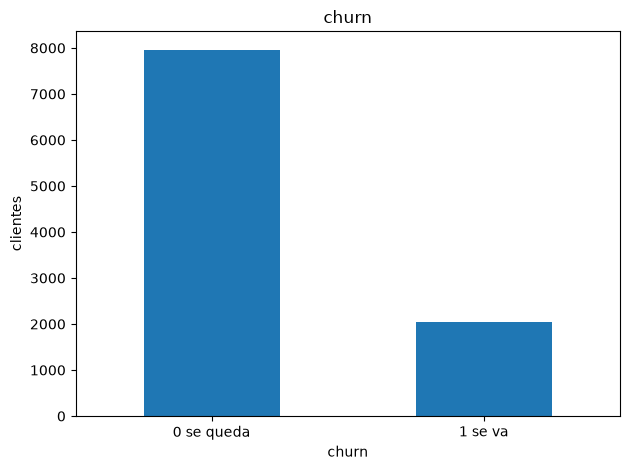

In [11]:

print(df_limpio['churn'].value_counts().sort_index())
print()
imprimir_tasa(df_limpio['churn'].value_counts(normalize=True).sort_index())

df_limpio['churn'].value_counts().sort_index().plot(kind='bar')
plt.xticks([0, 1], ['0 se queda', '1 se va'], rotation=0)
plt.xlabel('churn')
plt.ylabel('clientes')
plt.title('churn')
plt.tight_layout()
plt.show()


`churn` está desbalanceada, sin nulos: **79.6% se quedan y 20.4% se van**.

Para el modelo, accuracy sola va a verse bien aunque el clasificador diga siempre "se queda" (acertaría ~80% y no encontraría a nadie). Las métricas que le importan a FinAlpes son las que miran a la clase 1: a quién se contacta y a cuántos de los que sí se iban se alcanza a tocar. Eso se retoma en la evaluación.

La línea base de negocio del enunciado es ~15%. Acá el evento es más frecuente. Al pasar el modelo a un banco de 20,000 clientes hay que volver a estimar la tasa, no heredar este 20.4%.


## 1.6. Atributos que consideramos más importantes

El objetivo de negocio es priorizar a quién ofrecerle una campaña de retención. Una variable sirve si mueve la tasa de abandono respecto al 20.4% global, y si el movimiento es interpretable.

El orden de abajo es el de la señal, no el del archivo. `products_number` casi no correlaciona en lineal y aun así es de las más útiles: la relación no es una recta. Por eso no se descarta nada solo con la correlación.


### 1.6.1. Edad

Variable **numérica**. En crudo el mínimo es -1 y el máximo 210, y eso infla la kurtosis. Ya anulamos esos seis valores. El análisis es sobre la edad válida.


In [12]:
print(df_limpio['age'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))
print("Sesgo:", df_limpio['age'].skew())
print("Kurtosis:", df_limpio['age'].kurtosis())
print("Nulos:", int(df_limpio['age'].isna().sum()))
print()
print(df_limpio.groupby('churn')['age'].agg(['count', 'mean', 'median']))


count   9694.00
mean      38.92
std       10.47
min       18.00
1%        21.00
5%        25.00
25%       32.00
50%       37.00
75%       44.00
95%       60.00
99%       72.00
max       92.00
Name: age, dtype: float64
Sesgo: 0.9960784706688375
Kurtosis: 1.3249883233666815
Nulos: 306

       count  mean  median
churn                     
0       7709 37.41   36.00
1       1985 44.77   45.00


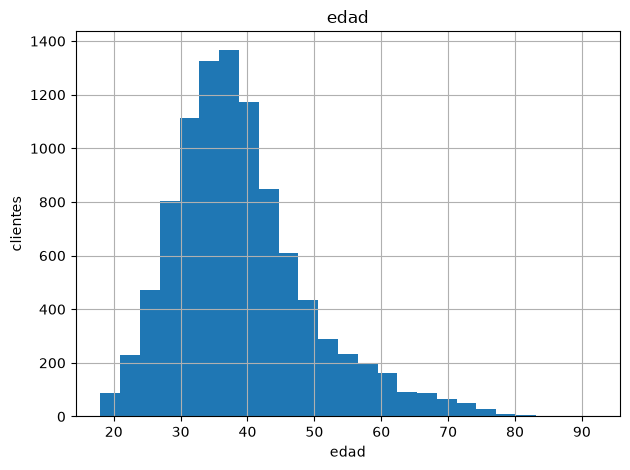

In [13]:
df_limpio['age'].hist(bins=25)
plt.xlabel('edad')
plt.ylabel('clientes')
plt.title('edad')
plt.tight_layout()
plt.show()


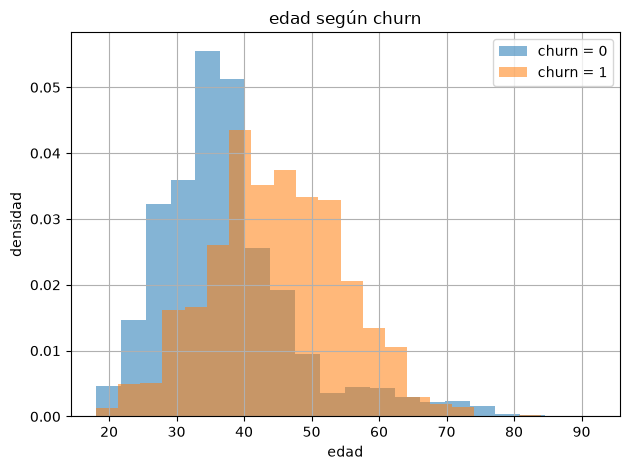

In [14]:
df_limpio.loc[df_limpio['churn'] == 0, 'age'].hist(bins=20, density=True, alpha=0.55, label='churn = 0')
df_limpio.loc[df_limpio['churn'] == 1, 'age'].hist(bins=20, density=True, alpha=0.55, label='churn = 1')
plt.xlabel('edad')
plt.ylabel('densidad')
plt.title('edad según churn')
plt.legend()
plt.tight_layout()
plt.show()


       count  mean
age               
18-30   1910  7.7%
31-40   4304 12.3%
41-50   2252 33.8%
51-60    782 56.0%
61+      446 24.7%


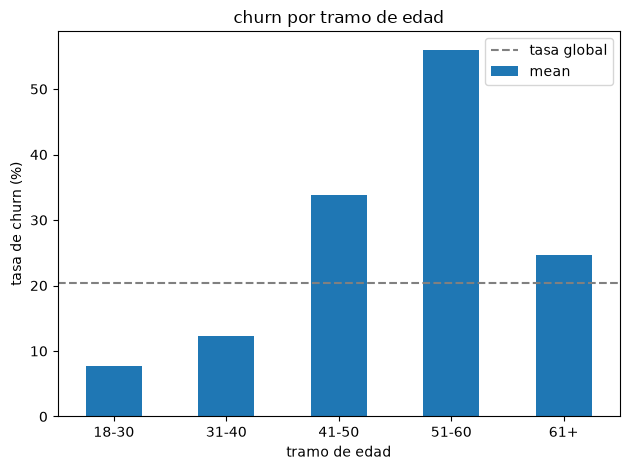

In [15]:

tramo_edad = pd.cut(
    df_limpio['age'],
    bins=[17, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '61+'],
)

tasa_edad = df_limpio.groupby(tramo_edad, observed=False)['churn'].agg(['count', 'mean'])
imprimir_tasa(tasa_edad)

(tasa_edad['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('tramo de edad')
plt.ylabel('tasa de churn (%)')
plt.title('churn por tramo de edad')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


La edad **sí separa**, y no de forma pareja.

- Mediana **37 años**. Sesgo ~1.0: cola hacia los mayores, ya sin el 210. Kurtosis ~1.3.
- Quien se queda tiene mediana **36**. Quien se va, mediana **45**. Nueve años de diferencia.
- La tasa por tramo: **18-30 → 7.7%** (1,910), **31-40 → 12.3%** (4,304), **41-50 → 33.8%** (2,252), **51-60 → 56.0%** (782), **61+ → 24.7%** (446).
- El tramo de 51 a 60 es el más chico de los de abajo de 60 y el de mayor riesgo: más de la mitad se va. Después de 60 la tasa baja. Una recta (más edad, más abandono) se equivoca en los mayores.
- Para la campaña, la edad entra mejor en tramos que como un solo coeficiente. Los nulos (306) se imputan en train.


### 1.6.2. País


country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

country
France    50.1%
Germany   25.1%
Spain     24.8%
Name: proportion, dtype: float64
Nulos: 0


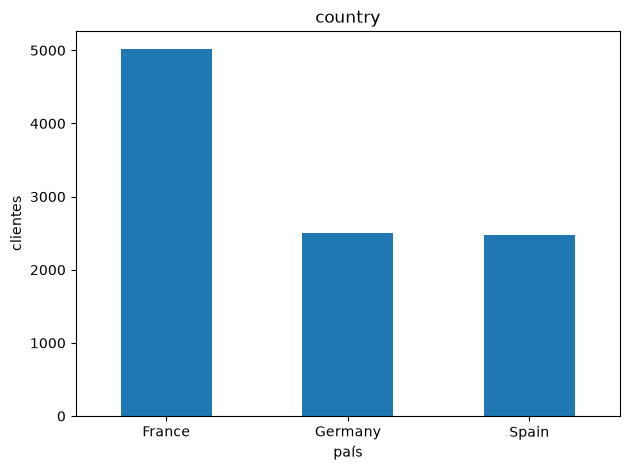

In [16]:

print(df_limpio['country'].value_counts(dropna=False))
print()
imprimir_tasa(df_limpio['country'].value_counts(normalize=True))
print("Nulos:", int(df_limpio['country'].isna().sum()))

df_limpio['country'].value_counts().plot(kind='bar')
plt.xlabel('país')
plt.ylabel('clientes')
plt.title('country')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


         count  sum  mean
country                  
Germany   2509  814 32.4%
Spain     2477  413 16.7%
France    5014  810 16.2%


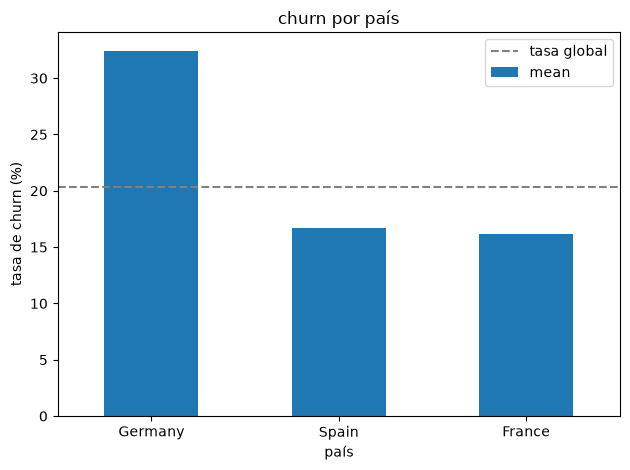

In [17]:

tasa_pais = df_limpio.groupby('country')['churn'].agg(['count', 'sum', 'mean']).sort_values('mean', ascending=False)
imprimir_tasa(tasa_pais)

(tasa_pais['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('país')
plt.ylabel('tasa de churn (%)')
plt.title('churn por país')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


`country` queda en **3 categorías**, sin nulos. La mitad de la muestra es Francia.

- France **5,014 (50.1%)**, tasa **16.2%** (810 abandonos).
- Spain **2,477 (24.8%)**, tasa **16.7%** (413).
- Germany **2,509 (25.1%)**, tasa **32.4%** (814).

Alemania es un cuarto de los clientes y **814 de los 2,037 abandonos (40.0%)**: casi los mismos que Francia, con la mitad de gente. Francia y España se parecen. El país entra como categoría. No hay un orden entre los tres.


### 1.6.3. Número de productos

Variable **discreta**, de 1 a 4. Se mira como categoría: el paso de 1 a 2 no se parece al paso de 2 a 3.


products_number
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

products_number
1   50.8%
2   45.9%
3    2.7%
4    0.6%
Name: proportion, dtype: float64


                 count   sum   mean
products_number                    
1                 5084  1409  27.7%
2                 4590   348   7.6%
3                  266   220  82.7%
4                   60    60 100.0%


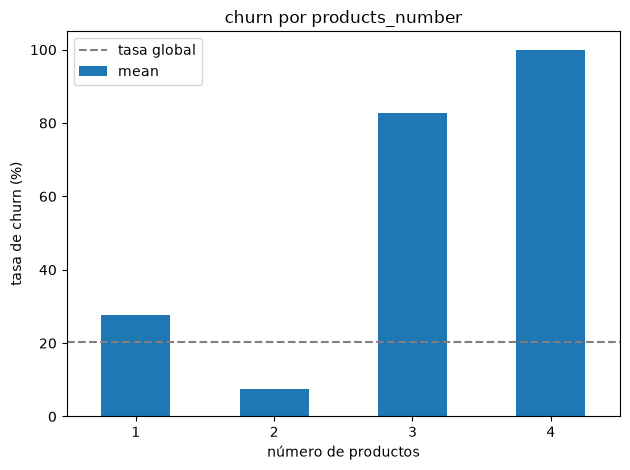

In [18]:

print(df_limpio['products_number'].value_counts().sort_index())
print()
imprimir_tasa(df_limpio['products_number'].value_counts(normalize=True).sort_index())

tasa_prod = df_limpio.groupby('products_number')['churn'].agg(['count', 'sum', 'mean'])
imprimir_tasa(tasa_prod)

(tasa_prod['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('número de productos')
plt.ylabel('tasa de churn (%)')
plt.title('churn por products_number')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:

# Cruce con actividad: el caso de un solo producto inactivo concentra abandono
cruce_tasa = df_limpio.pivot_table(
    index='products_number',
    columns='active_member',
    values='churn',
    aggfunc='mean',
)
cruce_n = df_limpio.pivot_table(
    index='products_number',
    columns='active_member',
    values='churn',
    aggfunc='count',
)
print('Tasa')
imprimir_tasa(cruce_tasa)
print()
print('Clientes')
print(cruce_n)


Tasa
active_member        0      1
products_number              
1                36.7%  18.9%
2                 9.9%   5.6%
3                88.2%  75.2%
4               100.0% 100.0%

Clientes
active_member       0     1
products_number            
1                2521  2563
2                2144  2446
3                 153   113
4                  31    29


`products_number` es de las señales más fuertes, y es **no lineal**.

- **1 producto:** 5,084 clientes (50.8%), tasa **27.7%**. Aportan **1,409 de 2,037 abandonos (69.2%)**.
- **2 productos:** 4,590 (45.9%), tasa **7.6%**. Es el grupo que se queda.
- **3 productos:** 266 (2.7%), tasa **82.7%**.
- **4 productos:** 60 (0.6%), tasa **100%** (60 de 60). Son pocos; la tasa perfecta no se puede leer como una ley, pero el grupo sí es de riesgo alto.
- Juntos, 3 y 4 productos son **326 clientes (3.3% de la base) y 280 abandonos**.

El cliente con dos productos es el de menor riesgo. El de uno solo ya está por encima del promedio, y con tres o cuatro el abandono es la norma. Meter esta variable como número en una regresión lineal le asignaría un solo signo y se come justo este quiebre. En el modelo va como categoría.

El cruce con actividad refuerza el foco: **un producto e inactivo** está en **36.7%** de abandono (2,521 clientes). Dos productos, activo o no, se mantiene bajo.


### 1.6.4. Cliente activo


active_member
0    4849
1    5151
Name: count, dtype: int64

               count   sum  mean
active_member                   
0               4849  1302 26.9%
1               5151   735 14.3%


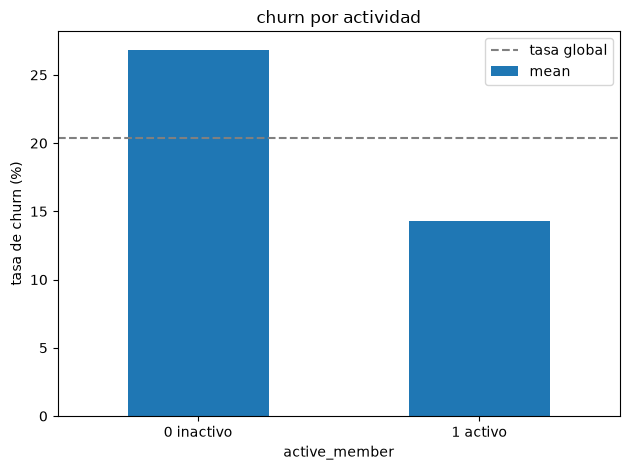

In [20]:

print(df_limpio['active_member'].value_counts().sort_index())
print()
tasa_activo = df_limpio.groupby('active_member')['churn'].agg(['count', 'sum', 'mean'])
imprimir_tasa(tasa_activo)

(tasa_activo['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xticks([0, 1], ['0 inactivo', '1 activo'], rotation=0)
plt.xlabel('active_member')
plt.ylabel('tasa de churn (%)')
plt.title('churn por actividad')
plt.legend()
plt.tight_layout()
plt.show()


`active_member` es binaria, sin nulos, partida casi a la mitad.

- Inactivo: **4,849** clientes, tasa **26.9%**, **1,302 abandonos (63.9% de todos los que se van)**.
- Activo: **5,151** clientes, tasa **14.3%**.

El inactivo abandona casi al doble. Es un criterio directo para la campaña: si hay que ordenar a quién llamar, el inactivo va antes que el activo, en igualdad del resto. No dice por qué está inactivo (puede ser que ya se estaba yendo). Es asociación, no causa.


### 1.6.5. Sexo


gender
Male      5457
Female    4543
Name: count, dtype: int64

        count   sum  mean
gender                   
Female   4543  1139 25.1%
Male     5457   898 16.5%

Tasa por país y sexo


gender   Female  Male
country              
France    20.3% 12.7%
Germany   37.6% 27.8%
Spain     21.2% 13.1%
Clientes
gender   Female  Male
country              
France     2261  2753
Germany    1193  1316
Spain      1089  1388


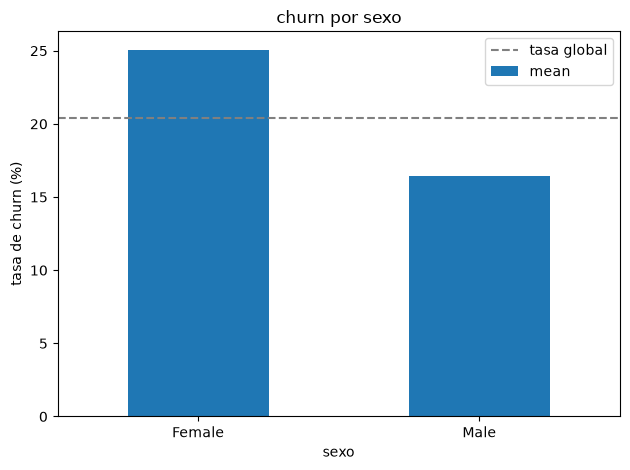

In [21]:

print(df_limpio['gender'].value_counts())
print()
tasa_sexo = df_limpio.groupby('gender')['churn'].agg(['count', 'sum', 'mean'])
imprimir_tasa(tasa_sexo)

print()
print('Tasa por país y sexo')
imprimir_tasa(df_limpio.pivot_table(index='country', columns='gender', values='churn', aggfunc='mean'))
print('Clientes')
print(df_limpio.pivot_table(index='country', columns='gender', values='churn', aggfunc='count'))

(tasa_sexo['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('sexo')
plt.ylabel('tasa de churn (%)')
plt.title('churn por sexo')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


`gender` queda en dos categorías, sin nulos.

- Female: **4,543 (45.4%)**, tasa **25.1%**, **1,139 abandonos**.
- Male: **5,457 (54.6%)**, tasa **16.5%**, **898 abandonos**.

Las mujeres son menos de la mitad de la base y más de la mitad de los abandonos. La brecha se mantiene dentro de cada país. El caso más alto del cruce es **mujer en Alemania (37.6%)**; el más bajo, **hombre en Francia (12.7%)**. El sexo entra como categoría. No alcanza para definir la campaña solo, y se usa junto con país, productos y actividad.


### 1.6.6. Saldo

Variable **numérica**, con una masa grande en cero. El cero se conserva: es un estado de la cuenta, no un dato faltante. Los 200 nulos de `balance` sí son huecos y no se mezclan con el cero.


In [22]:

print(df_limpio['balance'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))
print('Sesgo:', df_limpio['balance'].skew())
print('Kurtosis:', df_limpio['balance'].kurtosis())
print('Ceros:', int((df_limpio['balance'] == 0).sum()))
print('Proporción de ceros sobre filas:', f"{(df_limpio['balance'] == 0).mean():.1%}")
print('Proporción de ceros sobre saldos conocidos:', f"{(df_limpio['balance'] == 0).sum() / df_limpio['balance'].notna().sum():.1%}")
print('Nulos:', int(df_limpio['balance'].isna().sum()))
print()
print('Ceros por país (sobre saldos conocidos):')
imprimir_tasa(
    df_limpio.groupby('country')['balance'].apply(lambda s: (s == 0).sum() / s.notna().sum())
)


count     9800.00
mean     76286.25
std      62413.45
min          0.00
1%           0.00
5%           0.00
25%          0.00
50%      97038.69
75%     127537.15
95%     162488.12
99%     186103.65
max     250898.09
Name: balance, dtype: float64
Sesgo: -0.13653786331635326
Kurtosis: -1.4927656007606487
Ceros: 3559
Proporción de ceros sobre filas: 35.6%
Proporción de ceros sobre saldos conocidos: 36.3%
Nulos: 200

Ceros por país (sobre saldos conocidos):
country
France    48.4%
Germany    0.0%
Spain     48.7%
Name: balance, dtype: float64


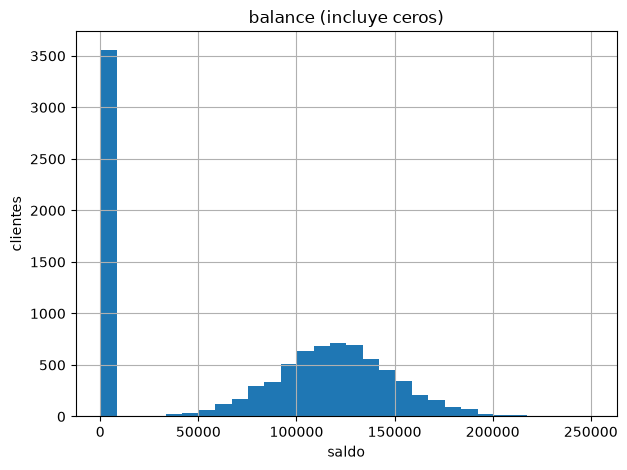

In [23]:
df_limpio['balance'].hist(bins=30)
plt.xlabel('saldo')
plt.ylabel('clientes')
plt.title('balance (incluye ceros)')
plt.tight_layout()
plt.show()


count     6241.00
mean    119789.34
std      30086.06
min       3768.69
5%       70362.52
25%     100212.13
50%     119825.75
75%     139301.68
95%     169902.92
max     250898.09
Name: balance, dtype: float64
Sesgo: 0.022589246099987047
Kurtosis: 0.2141158035625979

       count    median      mean
churn                           
0       4734 119796.97 119514.96
1       1507 119852.01 120651.26


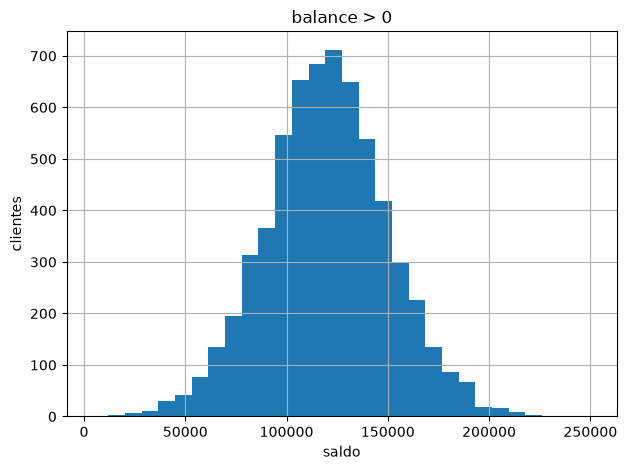

In [24]:
# Sin el cero, para ver la forma del saldo de quien sí tiene plata en la cuenta
saldo_positivo = df_limpio.loc[df_limpio['balance'] > 0, 'balance']
print(saldo_positivo.describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]))
print("Sesgo:", saldo_positivo.skew())
print("Kurtosis:", saldo_positivo.kurtosis())
print()
print(df_limpio.loc[df_limpio['balance'] > 0].groupby('churn')['balance'].agg(['count', 'median', 'mean']))

saldo_positivo.hist(bins=30)
plt.xlabel('saldo')
plt.ylabel('clientes')
plt.title('balance > 0')
plt.tight_layout()
plt.show()


In [25]:

# Los nulos de balance no entran en este corte, para no mezclarlos con el cero
con_saldo_conocido = df_limpio.loc[df_limpio['balance'].notna()].copy()
con_saldo_conocido['tiene_saldo'] = con_saldo_conocido['balance'].gt(0).map({True: 'con saldo', False: 'saldo 0'})
tasa_saldo = con_saldo_conocido.groupby(['country', 'tiene_saldo'])['churn'].agg(['count', 'mean'])
imprimir_tasa(tasa_saldo)


                     count  mean
country tiene_saldo             
France  con saldo     2536 18.3%
        saldo 0       2375 14.0%
Germany con saldo     2456 32.5%
Spain   con saldo     1249 19.5%
        saldo 0       1184 13.8%


El histograma crudo no es una campana. **3,559 clientes tienen saldo 0** (36.3% de los saldos conocidos). Sesgo -0.14 y kurtosis -1.49: la masa en cero aplana la distribución y baja la media (**76,286**) por debajo de la mediana (**97,039**).

Alemania tiene **cero clientes con saldo 0**. Francia está en **48.4%** y España en **48.7%**, sobre los saldos conocidos.

Si se mira solo a quien tiene saldo positivo (6,241 clientes), el monto ya sí es simétrico: mediana **~119,800**, sesgo ~0.02. Y **deja de separar el abandono**: mediana 119,797 si se queda y 119,852 si se va.

La tasa, partida por país:

- Francia, saldo 0: **14.0%**. Francia, con saldo: **18.3%**.
- España, saldo 0: **13.8%**. España, con saldo: **19.5%**.
- Alemania no tiene ceros. Con saldo informado: **32.5%**.

El monto del saldo, entre quienes lo tienen, no dice quién se va. Lo que sí se ve es el **estado** saldo = 0, y está mezclado con el país: Alemania no tiene ceros y es el país de mayor abandono. Por eso un modelo que use `balance` como número continuo se puede quedar con el efecto de Alemania. Conviene llevar el cero como indicador propio y no borrar esos registros. Los 200 nulos se imputan en train; no se rellenan con cero.


## 1.7. Variables que casi no separan

`credit_score`, `tenure`, `estimated_salary` y `credit_card` se revisan igual, para no dejarlas fuera del reporte. La conclusión es que mueven poco la tasa.


In [26]:
for col in ['credit_score', 'tenure', 'estimated_salary']:
    print("=" * 60)
    print(col)
    print(df_limpio[col].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))
    print("Sesgo:", df_limpio[col].skew())
    print("Kurtosis:", df_limpio[col].kurtosis())
    print("Nulos:", int(df_limpio[col].isna().sum()))
    print(df_limpio.groupby('churn')[col].agg(['count', 'median', 'mean']))
    print()


credit_score
count   9746.00
mean     650.62
std       96.62
min      350.00
1%       432.00
5%       490.00
25%      584.00
50%      652.00
75%      718.00
95%      812.00
99%      850.00
max      850.00
Name: credit_score, dtype: float64
Sesgo: -0.06760008899391173
Kurtosis: -0.43825532377249893
Nulos: 254
       count  median   mean
churn                      
0       7769  654.00 651.98
1       1977  646.00 645.31

tenure
count   9997.00
mean       5.01
std        2.89
min        0.00
1%         0.00
5%         1.00
25%        3.00
50%        5.00
75%        7.00
95%        9.00
99%       10.00
max       10.00
Name: tenure, dtype: float64
Sesgo: 0.01044828090237175
Kurtosis: -1.1648933831919532
Nulos: 3
       count  median  mean
churn                     
0       7960    5.00  5.03
1       2037    5.00  4.93

estimated_salary
count     9647.00
mean    100069.67
std      57484.03
min         11.58
1%        1798.62
5%        9991.68
25%      51106.18
50%     100137.70
75%     14937

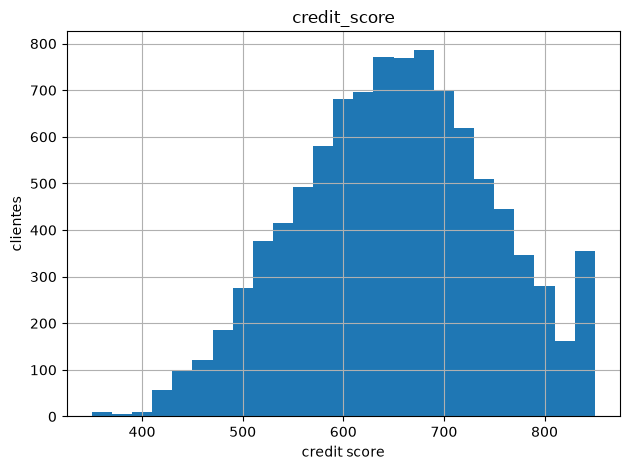

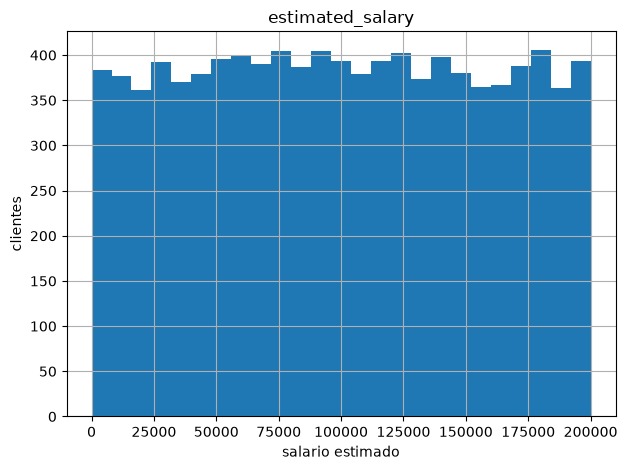

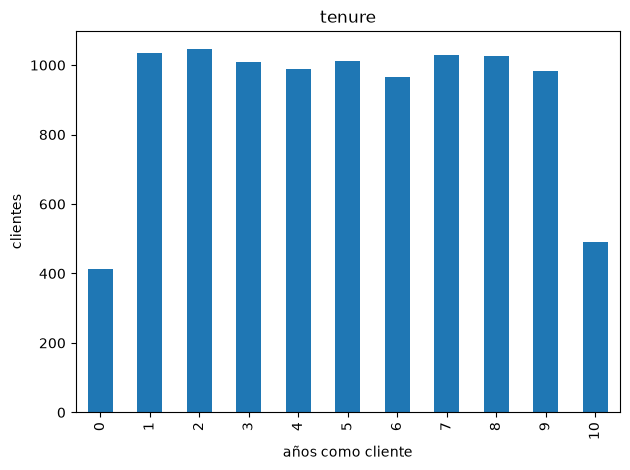

In [27]:
df_limpio['credit_score'].hist(bins=25)
plt.xlabel('credit score')
plt.ylabel('clientes')
plt.title('credit_score')
plt.tight_layout()
plt.show()

df_limpio['estimated_salary'].hist(bins=25)
plt.xlabel('salario estimado')
plt.ylabel('clientes')
plt.title('estimated_salary')
plt.tight_layout()
plt.show()

df_limpio['tenure'].dropna().astype(int).value_counts().sort_index().plot(kind='bar')
plt.xlabel('años como cliente')
plt.ylabel('clientes')
plt.title('tenure')
plt.tight_layout()
plt.show()


        count  mean
tenure             
0         413 23.0%
1        1034 22.4%
2        1046 19.2%
3        1009 21.1%
4         989 20.5%
5        1012 20.7%
6         967 20.3%
7        1028 17.2%
8        1025 19.2%
9         984 21.6%
10        490 20.6%

             count   sum  mean
credit_card                   
0             2945   613 20.8%
1             7055  1424 20.2%


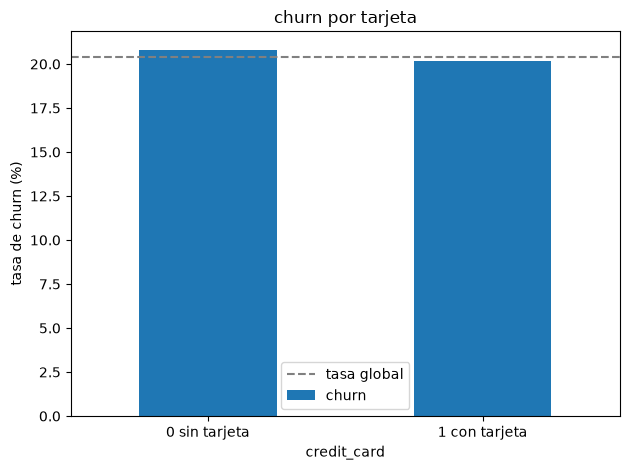

In [28]:

tasa_tenure = df_limpio.groupby('tenure', dropna=True)['churn'].agg(['count', 'mean'])
tasa_tenure.index = tasa_tenure.index.astype(int)
imprimir_tasa(tasa_tenure)
print()
imprimir_tasa(df_limpio.groupby('credit_card')['churn'].agg(['count', 'sum', 'mean']))

(df_limpio.groupby('credit_card')['churn'].mean() * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xticks([0, 1], ['0 sin tarjeta', '1 con tarjeta'], rotation=0)
plt.xlabel('credit_card')
plt.ylabel('tasa de churn (%)')
plt.title('churn por tarjeta')
plt.legend()
plt.tight_layout()
plt.show()


- **`credit_score`.** Después de anular 95, 120, 999 y 1200, el rango válido es 350 a 850. Mediana **652**, sesgo ~0. La mediana de quien se va es **646** y la de quien se queda **654**. Ocho puntos, sobre una escala de 500. Se conserva, con señal débil. 254 nulos, a imputar en train.
- **`tenure`.** Enteros de 0 a 10, bastante parejos entre 1 y 9, con menos gente en 0 (413) y en 10 (490). La tasa se mueve entre **17% y 23%**, sin una tendencia clara con los años. Los tres valores raros (-2, 15, 25) ya quedaron nulos.
- **`estimated_salary`.** Casi uniforme entre ~12 y 200,000: sesgo ~0 y kurtosis ~-1.2 (más plana que una normal). Mediana **99,654** si se queda y **102,127** si se va. No alcanza para priorizar. Los negativos ya se anularon; quedan 353 nulos.
- **`credit_card`.** **7,055** clientes (70.6%) tienen tarjeta. Tasa **20.2%** con tarjeta y **20.8%** sin tarjeta. Prácticamente la tasa global. Se deja en el archivo porque viene completa y es barata de incluir; no es un criterio de focalización.


## 1.8. Qué singifica esto para el modelo

In [29]:
# Correlación lineal con churn. products_number sale cerca de cero y aun así es útil: la relación no es una recta.
columnas = [
    'credit_score', 'age', 'tenure', 'balance', 'products_number',
    'credit_card', 'active_member', 'estimated_salary', 'churn',
]
print(df_limpio[columnas].corr(numeric_only=True)['churn'].sort_values())


active_member      -0.16
products_number    -0.05
credit_score       -0.03
tenure             -0.01
credit_card        -0.01
estimated_salary    0.01
balance             0.12
age                 0.28
churn               1.00
Name: churn, dtype: float64


La correlación lineal ordena bien edad (positiva), actividad (negativa) y saldo (positiva, por los ceros y por Alemania). Deja a `products_number` cerca de cero. Esa correlación no se usa para botar variables.

| Variable | Señal | Cómo entra |
|---|---|---|
| `age` | Fuerte y no lineal. Pico en 51-60 (56%), baja después de 60 | Numérica, con opción de tramos. Nulos: mediana de train |
| `country` | Alemania 32.4% contra ~16% en Francia y España. 40% de los abandonos | Categórica |
| `products_number` | 2 productos protege (7.6%). 1 está en 27.7%. 3 y 4 están por encima de 80% | Categórica, no como número lineal |
| `active_member` | Inactivo 26.9% contra activo 14.3%. 64% de los abandonos | Binaria |
| `gender` | Mujer 25.1% contra hombre 16.5%. Se sostiene dentro de cada país | Categórica |
| `balance` | El monto, si es > 0, no separa. El cero sí, y Alemania no tiene ceros | Conservar el 0. No imputar ceros. Nulos: mediana de train |
| `credit_score` | Mediana 646 contra 654 | Se conserva. Señal débil |
| `tenure` | Tasa plana, entre 17% y 23% | Se conserva. Señal débil |
| `estimated_salary` | Casi uniforme. Medianas 99.7 mil contra 102 mil | Se conserva. Señal débil |
| `credit_card` | 20.2% contra 20.8% | Se conserva. Casi no separa |

`df_limpio` es el que sigue: 10,000 filas, etiquetas unificadas, duplicados fuera, imposibles en nulo. No está imputado ni codificado. Eso se hace al partir train y test, para que el ajuste no vea el conjunto de prueba.

Para focalizar, antes incluso del modelo, los grupos que más se despegan del 20.4% son: **51-60 años**, **Alemania**, **3 o 4 productos**, **un solo producto e inactivo**, y **mujer**. Dos productos es el grupo que menos se va.


# 2. Entrenamiento del modelo

Se va a predecir `churn` con los datos curados, `df_limpio`. En la sección 1 se pudo ver que la relación entre productos y churn no es lineal. Con 2 productos la tasa baja a 7.6% y con 3 o 4 productos pasa de 80%. Con la edad pasa algo parecido, ya que la tasa sube hasta el tramo de 51 a 60 años (56%) y después baja.

Teniendo en cuenta lo anterior, se probaron cinco modelos, todos con la misma división de datos y el mismo criterio de selección:

1. **Regresión logística**, como modelo base.
2. **Regresión logística con términos polinomiales de grado 2**, con regularización L1 y L2, para ver si agregando cuadrados e interacciones el modelo lineal logra capturar mejor la edad y los productos.
3. **SVM con kernel RBF**.
4. **Random forest**.
5. **Gradient boosting**, usando `HistGradientBoostingClassifier` de sklearn.


## 2.1. División de los datos

Se separó el 80% de los clientes para entrenamiento y el 20% para prueba. La división es estratificada por `churn` para que en las dos partes quede una tasa de abandono parecida al 20.4% original, y se fijó `random_state=42` para que siempre salga la misma división.

Para escoger los hiperparámetros de cada modelo se usó validación cruzada estratificada de 5 folds sobre el conjunto de entrenamiento. El conjunto de prueba solo se usa al final para medir los modelos ya ajustados.


In [30]:
# Semilla para que la división y los modelos den lo mismo en cada ejecución
semilla = 42

datos = df_limpio.copy()

# products_number se deja como categoría
datos['products_number'] = datos['products_number'].astype(str)

# Indicador de saldo en cero. Queda nulo cuando el saldo es nulo.
# Se calcula fila por fila, por eso se puede hacer antes de dividir los datos.
datos['saldo_cero'] = pd.NA
con_saldo = datos['balance'].notna()
datos.loc[con_saldo, 'saldo_cero'] = datos.loc[con_saldo, 'balance'].eq(0).astype(float)

numericas = ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary']
binarias = ['credit_card', 'active_member', 'saldo_cero']
categoricas = ['country', 'gender', 'products_number']

for col in numericas + ['saldo_cero']:
    datos[col] = pd.to_numeric(datos[col], errors='coerce')

X = datos[numericas + binarias + categoricas]
y = datos['churn'].astype(int)

print('Nulos por columna antes de imputar:')
print(X.isna().sum())


Nulos por columna antes de imputar:
credit_score        254
age                 306
tenure                3
balance             200
estimated_salary    353
credit_card           0
active_member         0
saldo_cero          200
country               0
gender                0
products_number       0
dtype: int64


In [31]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=semilla,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semilla)

print('Train', X_train.shape[0], 'abandonos', int(y_train.sum()), f'({y_train.mean():.1%})')
print('Test ', X_test.shape[0], 'abandonos', int(y_test.sum()), f'({y_test.mean():.1%})')
print()
print('Productos en train')
print(X_train['products_number'].value_counts().sort_index())
print('Productos en test')
print(X_test['products_number'].value_counts().sort_index())


Train 8000 abandonos 1630 (20.4%)
Test  2000 abandonos 407 (20.3%)

Productos en train
products_number
1    4072
2    3661
3     221
4      46
Name: count, dtype: int64
Productos en test
products_number
1    1012
2     929
3      45
4      14
Name: count, dtype: int64


Entrenamiento quedó con 8,000 clientes y 1,630 abandonos (20.4%) y prueba con 2,000 clientes y 407 abandonos (20.3%), por lo que la tasa se mantiene en las dos partes. También se revisó que los clientes con 3 y 4 productos, que son pocos, quedaran repartidos en los dos conjuntos.


## 2.2. Preparación de las variables

Se usan todas las variables que quedaron al final de la sección 1, incluyendo las que mostraron poca relación con el churn, ya que algunos modelos pueden encontrar relaciones que no se ven en la correlación.

La preparación se hace dentro de un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada fold:

- Los nulos de las variables numéricas se reemplazan con la mediana. Si la mediana se calculara con todos los datos, el conjunto de prueba estaría influyendo en el entrenamiento.
- Los nulos de `balance` también se reemplazan con la mediana y no con cero, porque en la sección 1 vimos que los clientes con saldo en cero se comportan distinto al resto.
- País, sexo y número de productos se convierten en variables dummy con `OneHotEncoder`.
- Para la regresión logística y el SVM las variables numéricas se estandarizan, ya que estos modelos son sensibles a la escala y el saldo y el salario están en valores mucho más grandes que la edad. Para random forest y gradient boosting no se estandariza porque los árboles no dependen de la escala.


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix,
)

# Para logística y SVM (con estandarización)
preprocesar_escalado = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), numericas),
        ('bin', SimpleImputer(strategy='median'), binarias),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
    ]
)

# Para los modelos de árboles (sin estandarización)
preprocesar_arboles = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numericas),
        ('bin', SimpleImputer(strategy='median'), binarias),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categoricas),
    ]
)


def tabla_cv(busqueda):
    # Resultados de la búsqueda ordenados por F1 de validación
    res = pd.DataFrame(busqueda.cv_results_)
    cols = [c for c in res.columns if c.startswith('param_')]
    cols += ['mean_test_score', 'std_test_score', 'mean_train_score']
    tabla = res[cols].sort_values('mean_test_score', ascending=False).copy()
    tabla = tabla.rename(columns=lambda c: c.replace('param_modelo__', ''))
    for c in ['mean_test_score', 'std_test_score', 'mean_train_score']:
        tabla[c] = tabla[c].map(lambda v: f'{v:.3f}')
    return tabla.reset_index(drop=True)


## 2.3. Criterio de selección

Como el 80% de los clientes no abandona, un modelo que siempre prediga "no abandona" tendría una exactitud cercana al 80% sin encontrar a ningún cliente en riesgo. Por eso no se usó la exactitud para escoger los modelos. En la búsqueda de hiperparámetros se maximizó el **F1 de la clase 1** (abandono), que combina la precisión y el recall.

También se usó `class_weight='balanced'` en todos los modelos para darle más peso a la clase minoritaria durante el entrenamiento.

El umbral de clasificación se dejó en 0.5, que es el que usa `predict` por defecto. Este umbral se puede ajustar más adelante cuando se calcule el valor de la campaña, ya que depende del costo de contactar a cada cliente.


## 2.4. Regresión logística

Se probaron cuatro valores de `C` (0.01, 0.1, 1 y 10). Entre más pequeño es `C`, más fuerte es la regularización L2.


In [33]:
pipe_log = Pipeline([
    ('prep', preprocesar_escalado),
    ('modelo', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=semilla,
    )),
])

busqueda_log = GridSearchCV(
    pipe_log,
    param_grid={'modelo__C': [0.01, 0.1, 1, 10]},
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busqueda_log.fit(X_train, y_train)

print('Mejores parámetros:', busqueda_log.best_params_)
print(f'F1 validación: {busqueda_log.best_score_:.3f}')
print()
print(tabla_cv(busqueda_log).to_string(index=False))
print()
print('Columnas después del one-hot:')
print(list(busqueda_log.best_estimator_.named_steps['prep'].get_feature_names_out()))


Mejores parámetros: {'modelo__C': 10}
F1 validación: 0.557

    C mean_test_score std_test_score mean_train_score
10.00           0.557          0.010            0.558
 1.00           0.557          0.010            0.558
 0.10           0.556          0.011            0.557
 0.01           0.547          0.013            0.549

Columnas después del one-hot:
['num__credit_score', 'num__age', 'num__tenure', 'num__balance', 'num__estimated_salary', 'bin__credit_card', 'bin__active_member', 'bin__saldo_cero', 'cat__country_France', 'cat__country_Germany', 'cat__country_Spain', 'cat__gender_Female', 'cat__gender_Male', 'cat__products_number_1', 'cat__products_number_2', 'cat__products_number_3', 'cat__products_number_4']


## 2.5. Regresión logística con términos polinomiales

Se agregaron todos los términos de grado 2 (el cuadrado de cada variable y la interacción entre cada par de variables) con `PolynomialFeatures`. Esto aumenta bastante el número de columnas, por lo que se probó regularización L2 (Ridge) y L1 (Lasso). La L1 puede dejar en cero los coeficientes de los términos que no aportan.

- `l1_ratio`: 0 (L2) y 1 (L1)
- `C`: 0.01, 0.1 y 1

Se usó el solver `liblinear` porque permite las dos penalizaciones.


In [34]:
pipe_poli = Pipeline([
    ('prep', preprocesar_escalado),
    ('poli', PolynomialFeatures(degree=2, include_bias=False)),
    ('escala', StandardScaler()),
    ('modelo', LogisticRegression(
        solver='liblinear',
        max_iter=5000,
        class_weight='balanced',
        random_state=semilla,
    )),
])

busqueda_poli = GridSearchCV(
    pipe_poli,
    param_grid={
        'modelo__l1_ratio': [0.0, 1.0],
        'modelo__C': [0.01, 0.1, 1],
    },
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busqueda_poli.fit(X_train, y_train)

mejor_poli = busqueda_poli.best_estimator_
n_columnas = mejor_poli.named_steps['poli'].n_output_features_
coef = mejor_poli.named_steps['modelo'].coef_[0]

print('Mejores parámetros:', busqueda_poli.best_params_)
print(f'F1 validación: {busqueda_poli.best_score_:.3f}')
print('Columnas después de PolynomialFeatures:', n_columnas)
print('Coeficientes en cero:', int((coef == 0).sum()))
print()
print(tabla_cv(busqueda_poli).to_string(index=False))


Mejores parámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 1.0}
F1 validación: 0.577
Columnas después de PolynomialFeatures: 170
Coeficientes en cero: 91

   C  l1_ratio mean_test_score std_test_score mean_train_score
0.10      1.00           0.577          0.008            0.588
1.00      0.00           0.575          0.005            0.591
1.00      1.00           0.574          0.005            0.592
0.10      0.00           0.574          0.007            0.591
0.01      0.00           0.570          0.008            0.586
0.01      1.00           0.564          0.005            0.568


## 2.6. SVM

Se usó un SVM con kernel RBF, que permite separar las clases con una frontera no lineal. Se probaron:

- `C`: 0.3, 1 y 3
- `gamma`: 'scale', 0.01 y 0.1

Como `SVC` no entrega probabilidades por defecto, para calcular el AUC se usa `decision_function`.


In [35]:
pipe_svm = Pipeline([
    ('prep', preprocesar_escalado),
    ('modelo', SVC(
        kernel='rbf',
        class_weight='balanced',
        random_state=semilla,
    )),
])

busqueda_svm = GridSearchCV(
    pipe_svm,
    param_grid={
        'modelo__C': [0.3, 1, 3],
        'modelo__gamma': ['scale', 0.01, 0.1],
    },
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busqueda_svm.fit(X_train, y_train)

print('Mejores parámetros:', busqueda_svm.best_params_)
print(f'F1 validación: {busqueda_svm.best_score_:.3f}')
print()
print(tabla_cv(busqueda_svm).to_string(index=False))


Mejores parámetros: {'modelo__C': 3, 'modelo__gamma': 0.1}
F1 validación: 0.589

   C gamma mean_test_score std_test_score mean_train_score
3.00  0.10           0.589          0.008            0.657
1.00  0.10           0.589          0.011            0.630
3.00 scale           0.589          0.008            0.669
1.00 scale           0.589          0.011            0.640
0.30 scale           0.587          0.017            0.612
0.30  0.10           0.583          0.017            0.605
3.00  0.01           0.566          0.017            0.575
1.00  0.01           0.561          0.014            0.568
0.30  0.01           0.553          0.011            0.558


## 2.7. Random forest

Se probaron 12 combinaciones:

- `n_estimators`: 100 y 200
- `max_depth`: 6, 12 y sin límite
- `min_samples_leaf`: 5 y 20. Se incluyó porque hay grupos pequeños, como los 60 clientes con 4 productos, y con hojas muy pequeñas el modelo se puede aprender esos casos de memoria.


In [36]:
pipe_rf = Pipeline([
    ('prep', preprocesar_arboles),
    ('modelo', RandomForestClassifier(
        class_weight='balanced',
        random_state=semilla,
    )),
])

busqueda_rf = GridSearchCV(
    pipe_rf,
    param_grid={
        'modelo__n_estimators': [100, 200],
        'modelo__max_depth': [6, 12, None],
        'modelo__min_samples_leaf': [5, 20],
    },
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busqueda_rf.fit(X_train, y_train)

print('Mejores parámetros:', busqueda_rf.best_params_)
print(f'F1 validación: {busqueda_rf.best_score_:.3f}')
print()
print(tabla_cv(busqueda_rf).to_string(index=False))


Mejores parámetros: {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
F1 validación: 0.613

max_depth  min_samples_leaf  n_estimators mean_test_score std_test_score mean_train_score
       12                 5           200           0.613          0.018            0.767
       12                 5           100           0.610          0.017            0.763
     None                 5           200           0.608          0.014            0.793
     None                 5           100           0.605          0.019            0.792
       12                20           200           0.592          0.015            0.639
       12                20           100           0.592          0.014            0.639
     None                20           100           0.592          0.013            0.639
     None                20           200           0.591          0.014            0.639
        6                 5           100           0.588     

## 2.8. Gradient boosting

A diferencia de random forest, en gradient boosting los árboles se entrenan uno después del otro y cada árbol trata de corregir los errores de los anteriores. Se probaron 16 combinaciones:

- `learning_rate`: 0.03 y 0.1
- `max_iter` (número de árboles): 100 y 300
- `max_leaf_nodes`: 8 y 31
- `min_samples_leaf`: 20 y 50


In [37]:
pipe_gb = Pipeline([
    ('prep', preprocesar_arboles),
    ('modelo', HistGradientBoostingClassifier(
        early_stopping=False,
        class_weight='balanced',
        random_state=semilla,
    )),
])

busqueda_gb = GridSearchCV(
    pipe_gb,
    param_grid={
        'modelo__learning_rate': [0.03, 0.1],
        'modelo__max_iter': [100, 300],
        'modelo__max_leaf_nodes': [8, 31],
        'modelo__min_samples_leaf': [20, 50],
    },
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
busqueda_gb.fit(X_train, y_train)

print('Mejores parámetros:', busqueda_gb.best_params_)
print(f'F1 validación: {busqueda_gb.best_score_:.3f}')
print()
print(tabla_cv(busqueda_gb).to_string(index=False))


Mejores parámetros: {'modelo__learning_rate': 0.03, 'modelo__max_iter': 300, 'modelo__max_leaf_nodes': 31, 'modelo__min_samples_leaf': 20}
F1 validación: 0.613

 learning_rate  max_iter  max_leaf_nodes  min_samples_leaf mean_test_score std_test_score mean_train_score
          0.03       300              31                20           0.613          0.009            0.784
          0.03       300              31                50           0.611          0.015            0.770
          0.10       100               8                20           0.610          0.012            0.649
          0.03       100              31                50           0.609          0.013            0.670
          0.03       100              31                20           0.609          0.012            0.677
          0.10       300               8                50           0.608          0.012            0.714
          0.03       300               8                50           0.608          0.009 

## 2.9. Comparación y selección del modelo

Se escoge el modelo con el mayor F1 promedio en la validación cruzada. Después se evalúan los cinco modelos en el conjunto de prueba una sola vez, para confirmar que los resultados se mantienen con datos que no se usaron en el entrenamiento.


                 modelo  f1_validacion  desv_validacion  f1_train
0         Random forest         0.6135           0.0182    0.7672
1     Gradient boosting         0.6133           0.0089    0.7842
2                   SVM         0.5889           0.0076    0.6565
3  Logística polinomial         0.5765           0.0079    0.5879
4   Regresión logística         0.5573           0.0100    0.5584

Modelo elegido: Random forest


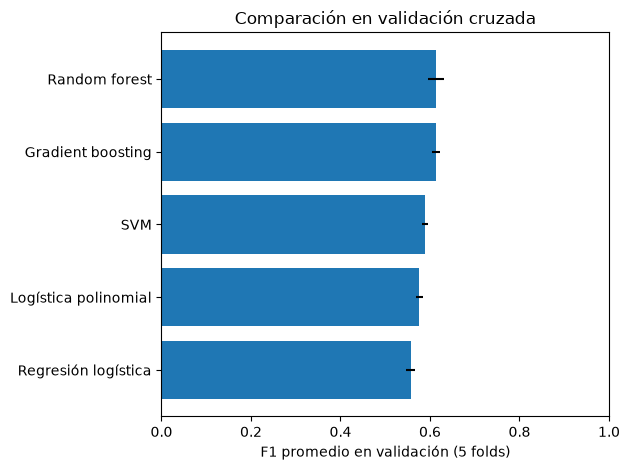

In [38]:
busquedas = {
    'Regresión logística': busqueda_log,
    'Logística polinomial': busqueda_poli,
    'SVM': busqueda_svm,
    'Random forest': busqueda_rf,
    'Gradient boosting': busqueda_gb,
}

filas = []
for nombre, busqueda in busquedas.items():
    i = busqueda.best_index_
    filas.append({
        'modelo': nombre,
        'f1_validacion': busqueda.cv_results_['mean_test_score'][i],
        'desv_validacion': busqueda.cv_results_['std_test_score'][i],
        'f1_train': busqueda.cv_results_['mean_train_score'][i],
    })

comparacion = pd.DataFrame(filas).sort_values('f1_validacion', ascending=False).reset_index(drop=True)
with pd.option_context('display.float_format', '{:.4f}'.format):
    print(comparacion)

nombre_elegido = comparacion.loc[0, 'modelo']
modelo_elegido = busquedas[nombre_elegido].best_estimator_
print()
print('Modelo elegido:', nombre_elegido)

orden = comparacion.sort_values('f1_validacion')
plt.barh(orden['modelo'], orden['f1_validacion'], xerr=orden['desv_validacion'])
plt.xlabel('F1 promedio en validación (5 folds)')
plt.xlim(0, 1)
plt.title('Comparación en validación cruzada')
plt.tight_layout()
plt.show()


In [39]:
def puntaje(modelo, X):
    # SVC no tiene predict_proba, se usa decision_function para el AUC
    if hasattr(modelo, 'predict_proba'):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)


filas = []
for nombre, busqueda in busquedas.items():
    modelo = busqueda.best_estimator_
    pred = modelo.predict(X_test)
    filas.append({
        'modelo': nombre,
        'f1': f1_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'auc': roc_auc_score(y_test, puntaje(modelo, X_test)),
        'marcados': int(pred.sum()),
        'abandonos_encontrados': int(((pred == 1) & (y_test == 1)).sum()),
    })

resultados_test = pd.DataFrame(filas).sort_values('f1', ascending=False).reset_index(drop=True)
print('Resultados en el conjunto de prueba (', int(y_test.sum()), 'abandonos de', len(y_test), 'clientes )')
with pd.option_context('display.float_format', '{:.3f}'.format):
    print(resultados_test)

print()
print('Matriz de confusión del modelo elegido:', nombre_elegido)
cm = confusion_matrix(y_test, modelo_elegido.predict(X_test))
print(pd.DataFrame(cm, index=['real 0', 'real 1'], columns=['pred 0', 'pred 1']))


Resultados en el conjunto de prueba ( 407 abandonos de 2000 clientes )
                 modelo    f1  precision  recall   auc  marcados  \
0     Gradient boosting 0.624      0.557   0.710 0.859       519   
1         Random forest 0.607      0.535   0.703 0.856       535   
2                   SVM 0.583      0.481   0.740 0.843       626   
3  Logística polinomial 0.576      0.471   0.742 0.850       641   
4   Regresión logística 0.568      0.453   0.762 0.829       685   

   abandonos_encontrados  
0                    289  
1                    286  
2                    301  
3                    302  
4                    310  

Matriz de confusión del modelo elegido: Random forest
        pred 0  pred 1
real 0    1344     249
real 1     121     286


## 2.10. Resultados

En la validación cruzada random forest y gradient boosting quedaron prácticamente empatados, con un F1 de 0.6135 y 0.6133. Siguiendo el criterio de la sección 2.9 se escogió random forest con profundidad máxima de 12, mínimo 5 clientes por hoja y 200 árboles. Sin embargo, la diferencia es tan pequeña que no alcanza para decir que uno sea mejor que el otro. Gradient boosting tuvo menos variación entre folds (desviación de 0.009 contra 0.018 de random forest).

Sobre los demás modelos:

- La regresión logística fue el modelo con el F1 más bajo (0.557). El valor de `C` casi no cambió el resultado, y el F1 de entrenamiento y el de validación son casi iguales (0.558 y 0.557), lo que indica que el modelo tiene subajuste más que sobreajuste.
- Al agregar los términos polinomiales el F1 subió a 0.577. El mejor resultado fue con L1 y `C=0.1`, que dejó en cero 91 de los 170 coeficientes. Esto muestra que parte del problema de la logística simple era que la edad y el número de productos no tienen una relación lineal con el churn.
- El SVM con kernel RBF llegó a 0.589, por encima de las dos logísticas pero por debajo de los modelos de árboles.
- En random forest, los árboles sin límite de profundidad tuvieron un F1 de entrenamiento de 0.79 sin mejorar en validación (0.608), y con `min_samples_leaf=20` el modelo bajó a 0.592.
- En gradient boosting, las combinaciones con `learning_rate=0.1`, 300 árboles y 31 hojas llegaron a un F1 de entrenamiento de 0.96 y bajaron a 0.596 en validación, que es un caso de sobreajuste.

En el conjunto de prueba los resultados fueron parecidos a los de validación. Los dos modelos de árboles quedaron arriba, seguidos del SVM y las dos logísticas. Gradient boosting obtuvo un F1 de 0.624 y random forest de 0.607, con un AUC de 0.859 y 0.856. Como el modelo se escogió con la validación, esta diferencia no cambia la elección, pero confirma que los dos modelos de árboles tienen un desempeño muy similar. En la sección 3 se va a comparar con más detalle cuál de los dos conviene para la campaña.

Los modelos lineales encuentran más abandonos en prueba (310 la regresión logística contra 286 de random forest), pero marcan muchos más clientes para lograrlo (685 contra 535), por lo que su precisión es más baja.


# 3. Análisis cuantitativo de resultados del modelo

En esta sección se calculan las métricas de los cinco modelos sobre el conjunto de prueba (2,000 clientes que no se usaron en el entrenamiento) y se explica qué significa cada una para FinAlpes. También se revisa si la diferencia entre random forest y gradient boosting es real o puede ser por azar, qué decisiones de la preparación ayudaron a las métricas y qué se podría mejorar.

Algunos análisis adicionales no se vieron en clase, y en cada uno se indica por qué se agregaron.


## 3.1. Métricas en el conjunto de prueba

Además de los cinco modelos se incluyen dos referencias sin modelo, para tener contra qué comparar:

- **No contactar a nadie.** Es lo que pasa hoy si no se hace campaña.
- **Contactar a todos.** Se le ofrece la campaña a toda la base sin usar el modelo.

Las dos referencias anteriores y el AUC-PR (precisión promedio) no se vieron en clase. El AUC-PR se incluyó porque resume la curva Precision-Recall en un solo número y es útil cuando la clase de interés es minoritaria, como en este caso.


In [40]:
from sklearn.metrics import accuracy_score, average_precision_score

def metricas(y_real, pred, score=None):
    vn, fp, fn, vp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {
        'exactitud': accuracy_score(y_real, pred),
        'precision': vp / (vp + fp) if (vp + fp) > 0 else 0.0,
        'recall': vp / (vp + fn),
        'especificidad': vn / (vn + fp),
        'f1': f1_score(y_real, pred, zero_division=0),
        'auc_roc': roc_auc_score(y_real, score) if score is not None else float('nan'),
        'auc_pr': average_precision_score(y_real, score) if score is not None else float('nan'),
        'contactados': int(vp + fp),
        'abandonos_encontrados': int(vp),
        'falsas_alarmas': int(fp),
        'abandonos_perdidos': int(fn),
    }


filas = []
for nombre, busqueda in busquedas.items():
    modelo = busqueda.best_estimator_
    fila = metricas(y_test, modelo.predict(X_test), puntaje(modelo, X_test))
    fila['modelo'] = nombre
    filas.append(fila)

fila = metricas(y_test, np.zeros(len(y_test), dtype=int))
fila['modelo'] = 'Referencia: no contactar a nadie'
filas.append(fila)

fila = metricas(y_test, np.ones(len(y_test), dtype=int))
fila['modelo'] = 'Referencia: contactar a todos'
filas.append(fila)

metricas_test = pd.DataFrame(filas).set_index('modelo')
with pd.option_context('display.float_format', '{:.3f}'.format, 'display.width', 200):
    print(metricas_test)


                                  exactitud  precision  recall  especificidad    f1  auc_roc  auc_pr  contactados  abandonos_encontrados  falsas_alarmas  abandonos_perdidos
modelo                                                                                                                                                                      
Regresión logística                   0.764      0.453   0.762          0.765 0.568    0.829   0.609          685                    310             375                  97
Logística polinomial                  0.778      0.471   0.742          0.787 0.576    0.850   0.667          641                    302             339                 105
SVM                                   0.784      0.481   0.740          0.796 0.583    0.843   0.656          626                    301             325                 106
Random forest                         0.815      0.535   0.703          0.844 0.607    0.856   0.682          535                    28

Lo que significa cada métrica para la campaña de FinAlpes:

- La **exactitud** es el porcentaje de clientes bien clasificados. No sirve para este problema, ya que no contactar a nadie tiene una exactitud de 0.796, más alta que la de la regresión logística (0.764), y no retiene a ningún cliente.
- La **precisión** es el porcentaje de los clientes contactados que sí iban a abandonar. Como el enunciado dice que se paga la campaña por cada cliente contactado, la precisión indica qué parte del presupuesto llega a clientes que de verdad la necesitaban. Con random forest es 0.535, o sea que un poco más de la mitad de los contactados se iban a ir.
- El **recall** es el porcentaje de los clientes que abandonan que la campaña alcanza a contactar. Random forest encuentra 286 de los 407 abandonos (0.703).
- La **especificidad** es el porcentaje de los clientes que se quedan que no se contactan. Con random forest es 0.844, por lo que se evita contactar a 1,344 de los 1,593 clientes que se iban a quedar.
- El **F1** combina precisión y recall en un solo número, y es el que se usó para escoger los hiperparámetros.
- El **AUC-ROC** mide qué tan bien ordena el modelo a los clientes por riesgo, sin depender del umbral. Un AUC de 0.856 quiere decir que si se toma un cliente que abandona y uno que se queda al azar, en el 85.6% de los casos el modelo le da más riesgo al que abandona.
- El **AUC-PR** (precisión promedio) es parecido al anterior pero se enfoca en la clase de abandono, por lo que es más útil cuando las clases están desbalanceadas. Un modelo al azar tendría 0.203, que es la tasa de abandono, y random forest tiene 0.682.

Los dos modelos de árboles tienen la mejor precisión, F1 y AUC. Los modelos lineales y el SVM encuentran un poco más de abandonos (entre 301 y 310) pero contactan entre 90 y 150 clientes más para lograrlo, por lo que su precisión baja a menos de 0.49.

Comparado con contactar a todos, random forest contacta al 27% de los clientes (535 de 2,000) y encuentra al 70% de los que se iban. La precisión pasa de 0.203 a 0.535, es decir que por cada cliente contactado hay 2.6 veces más probabilidad de estar contactando a alguien que se iba a ir.


## 3.2. Matrices de confusión de los dos mejores modelos


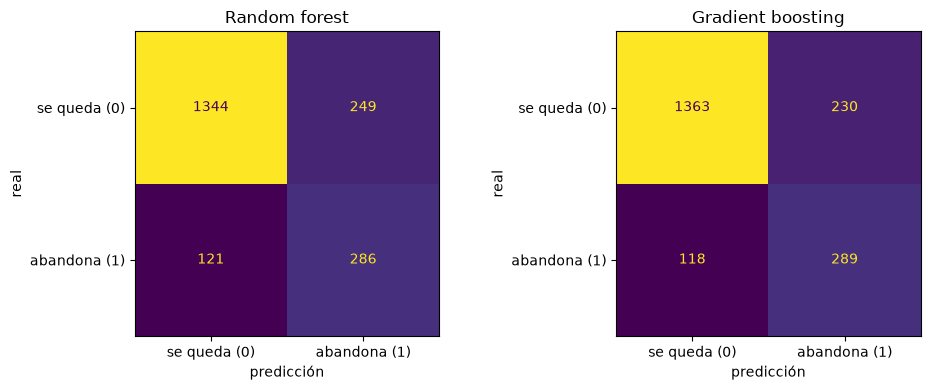

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, nombre in zip(ejes, ['Random forest', 'Gradient boosting']):
    modelo = busquedas[nombre].best_estimator_
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        modelo.predict(X_test),
        display_labels=['se queda (0)', 'abandona (1)'],
        colorbar=False,
        ax=eje,
    )
    eje.set_title(nombre)
    eje.set_xlabel('predicción')
    eje.set_ylabel('real')
plt.tight_layout()
plt.show()


Las dos matrices son muy parecidas. Gradient boosting encuentra 3 abandonos más (289 contra 286) y tiene 19 falsas alarmas menos (230 contra 249).

Para dar una idea del valor para la empresa, el enunciado supone que la campaña convence al 30% de los clientes que iban a abandonar. Con random forest, sobre estos 2,000 clientes se contactarían 535 y se retendrían cerca de 86 clientes (30% de 286). Si se contactara a todos se retendrían cerca de 122 (30% de 407), pero pagando 2,000 contactos en lugar de 535. Con el modelo se logra el 70% de la retención posible con el 27% de los contactos.

Si se lleva a un banco de 20,000 clientes con la misma tasa de abandono, serían unos 5,350 contactos, 2,860 abandonos encontrados y unos 860 clientes retenidos. Estos números son con la tasa de 20.4% de esta muestra. En la sección 5 se recalculan con la tasa del 15% del enunciado y con los costos de la campaña.

Los 121 abandonos que el modelo no detecta (30% del total) son clientes que se van a ir sin recibir ninguna oferta.


## 3.3. Curvas ROC y Precision-Recall

Estas curvas muestran el desempeño de cada modelo para todos los umbrales posibles, no solo para el umbral de 0.5.


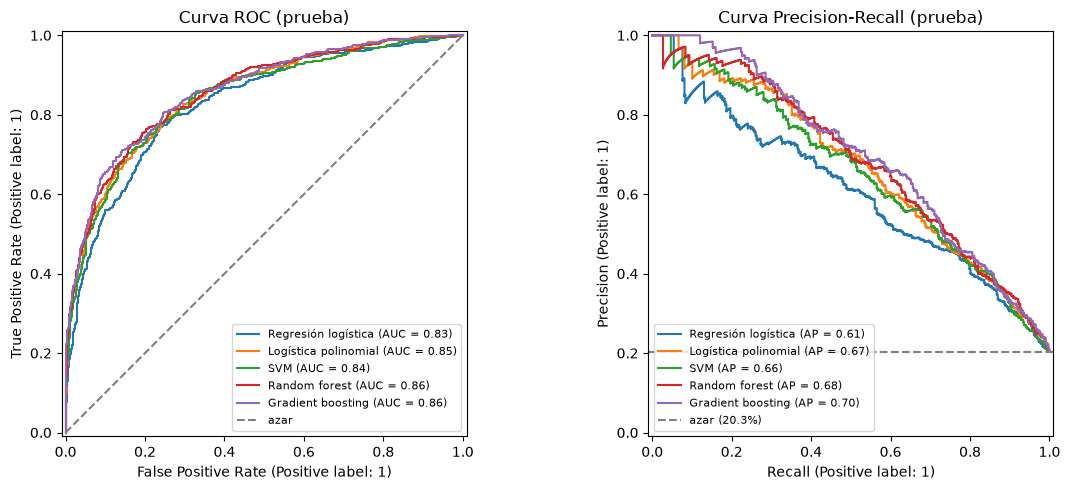

In [42]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, (eje_roc, eje_pr) = plt.subplots(1, 2, figsize=(12, 5))
for nombre, busqueda in busquedas.items():
    score = puntaje(busqueda.best_estimator_, X_test)
    RocCurveDisplay.from_predictions(y_test, score, name=nombre, ax=eje_roc)
    PrecisionRecallDisplay.from_predictions(y_test, score, name=nombre, ax=eje_pr)

eje_roc.plot([0, 1], [0, 1], color='gray', linestyle='--', label='azar')
eje_roc.set_title('Curva ROC (prueba)')
eje_roc.legend(fontsize=8)

eje_pr.axhline(y_test.mean(), color='gray', linestyle='--', label=f'azar ({y_test.mean():.1%})')
eje_pr.set_title('Curva Precision-Recall (prueba)')
eje_pr.legend(fontsize=8)

plt.tight_layout()
plt.show()


En la curva ROC los cinco modelos quedan muy por encima de la línea del azar y bastante juntos entre sí (AUC entre 0.83 y 0.86). La diferencia más visible es la regresión logística, que queda por debajo de los demás en la parte izquierda de la curva, que es donde están los clientes de mayor riesgo.

En la curva Precision-Recall la diferencia se ve más clara. Para un recall de 0.4, la regresión logística tiene una precisión cercana a 0.69, mientras que random forest y gradient boosting están alrededor de 0.78. Esto quiere decir que, si el banco solo pudiera contactar a pocos clientes, los modelos de árboles desperdician menos contactos.


## 3.4. Abandonos encontrados según cuántos clientes se contacten

En la práctica el banco no va a contactar a todos los que el modelo marque, sino a los que tengan el mayor riesgo según el presupuesto de la campaña. Por eso se ordenan los clientes de prueba de mayor a menor probabilidad de abandono y se revisa cuántos abandonos se encuentran contactando al 10%, 20%, 30%, etc.

El **lift** indica cuántas veces mejor es la precisión del modelo frente a escoger clientes al azar.

Esta tabla y la curva de ganancia acumulada no se vieron en clase. Se agregaron porque muestran el desempeño del modelo de la forma en que la campaña se usaría en la práctica, contactando primero a los clientes de mayor riesgo.


Random forest
contactados_%  contactados  abandonos_encontrados  precision  recall  lift
           5%          100                     93      0.930   0.229 4.570
          10%          200                    158      0.790   0.388 3.882
          20%          400                    251      0.627   0.617 3.084
          30%          600                    301      0.502   0.740 2.465
          40%          800                    334      0.417   0.821 2.052
          50%         1000                    360      0.360   0.885 1.769

Gradient boosting
contactados_%  contactados  abandonos_encontrados  precision  recall  lift
           5%          100                     95      0.950   0.233 4.668
          10%          200                    158      0.790   0.388 3.882
          20%          400                    260      0.650   0.639 3.194
          30%          600                    298      0.497   0.732 2.441
          40%          800                    338      0.422   0.83

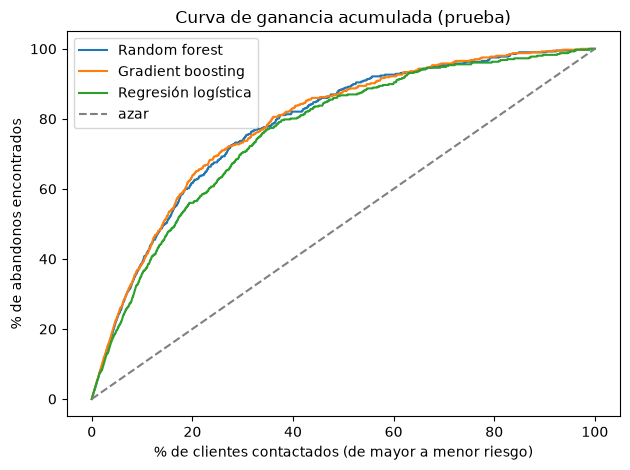

In [43]:
def tabla_ganancia(y_real, score, porcentajes=(0.05, 0.10, 0.20, 0.30, 0.40, 0.50)):
    orden = np.argsort(-np.asarray(score))
    y_ordenado = np.asarray(y_real)[orden]
    total_abandonos = y_ordenado.sum()
    tasa_base = y_ordenado.mean()
    filas = []
    for p in porcentajes:
        n = int(round(p * len(y_ordenado)))
        encontrados = int(y_ordenado[:n].sum())
        filas.append({
            'contactados_%': f'{p:.0%}',
            'contactados': n,
            'abandonos_encontrados': encontrados,
            'precision': encontrados / n,
            'recall': encontrados / total_abandonos,
            'lift': (encontrados / n) / tasa_base,
        })
    return pd.DataFrame(filas)


for nombre in ['Random forest', 'Gradient boosting', 'Regresión logística']:
    print(nombre)
    tabla = tabla_ganancia(y_test, puntaje(busquedas[nombre].best_estimator_, X_test))
    with pd.option_context('display.float_format', '{:.3f}'.format):
        print(tabla.to_string(index=False))
    print()

porcentajes = np.linspace(0, 1, 101)
for nombre in ['Random forest', 'Gradient boosting', 'Regresión logística']:
    score = puntaje(busquedas[nombre].best_estimator_, X_test)
    y_ordenado = np.asarray(y_test)[np.argsort(-np.asarray(score))]
    acumulado = np.concatenate([[0], np.cumsum(y_ordenado)]) / y_ordenado.sum()
    x = np.arange(len(acumulado)) / len(y_ordenado)
    plt.plot(x * 100, acumulado * 100, label=nombre)
plt.plot([0, 100], [0, 100], color='gray', linestyle='--', label='azar')
plt.xlabel('% de clientes contactados (de mayor a menor riesgo)')
plt.ylabel('% de abandonos encontrados')
plt.title('Curva de ganancia acumulada (prueba)')
plt.legend()
plt.tight_layout()
plt.show()


Si el banco tiene presupuesto para contactar solo a una parte de los clientes, el modelo ayuda bastante a escoger a quién:

- Contactando al 10% de mayor riesgo (200 clientes) se encuentran 158 abandonos, con una precisión de 0.79. Es casi 4 veces mejor que escoger al azar (lift de 3.9).
- Contactando al 20% (400 clientes) se encuentra el 62% de los abandonos con random forest y el 64% con gradient boosting. Con la regresión logística se encuentra el 56%.
- A partir del 30% las tres curvas casi se juntan, y cada cliente adicional que se contacta aporta menos abandonos.

Random forest y gradient boosting se comportan casi igual en toda la curva.


## 3.5. Intervalos de confianza con bootstrapping

Las métricas anteriores salen de una sola muestra de 2,000 clientes, por lo que pueden variar si se toma otra muestra. Con bootstrapping se remuestrea el conjunto de prueba con reemplazo (1,000 veces) y se calcula la métrica en cada remuestreo. Con los percentiles 2.5 y 97.5 se obtiene un intervalo de confianza del 95%.


Media e intervalo de confianza del 95%
                                        f1             precision                recall               auc_roc
modelo                                                                                                      
Regresión logística   0.568 [0.529, 0.604]  0.453 [0.414, 0.492]  0.760 [0.718, 0.803]  0.828 [0.803, 0.852]
Logística polinomial  0.576 [0.538, 0.612]  0.472 [0.432, 0.512]  0.741 [0.692, 0.782]  0.849 [0.826, 0.870]
SVM                   0.583 [0.548, 0.618]  0.482 [0.443, 0.520]  0.739 [0.691, 0.782]  0.843 [0.819, 0.864]
Random forest         0.607 [0.569, 0.643]  0.535 [0.493, 0.577]  0.701 [0.655, 0.744]  0.855 [0.834, 0.875]
Gradient boosting     0.625 [0.586, 0.661]  0.558 [0.516, 0.603]  0.710 [0.665, 0.754]  0.859 [0.837, 0.877]


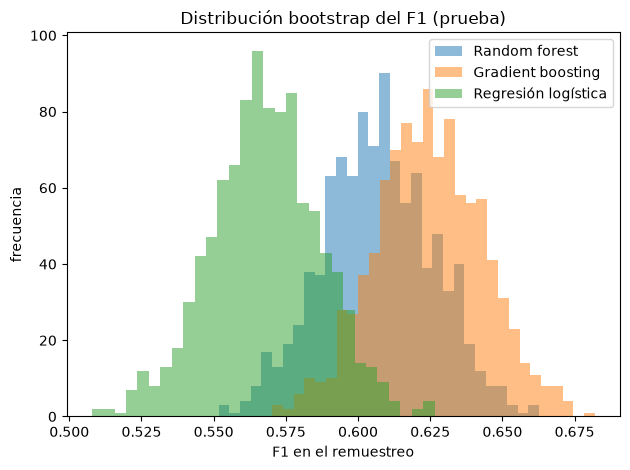

In [44]:
rng = np.random.default_rng(semilla)
n_bootstrap = 1000
y_arr = y_test.to_numpy()
n = len(y_arr)

predicciones = {nombre: b.best_estimator_.predict(X_test) for nombre, b in busquedas.items()}
puntajes = {nombre: puntaje(b.best_estimator_, X_test) for nombre, b in busquedas.items()}

muestras = [rng.integers(0, n, n) for _ in range(n_bootstrap)]

boot = {}
for nombre in busquedas:
    pred, score = predicciones[nombre], puntajes[nombre]
    valores = {'f1': [], 'precision': [], 'recall': [], 'auc_roc': []}
    for idx in muestras:
        valores['f1'].append(f1_score(y_arr[idx], pred[idx]))
        valores['precision'].append(precision_score(y_arr[idx], pred[idx]))
        valores['recall'].append(recall_score(y_arr[idx], pred[idx]))
        valores['auc_roc'].append(roc_auc_score(y_arr[idx], score[idx]))
    boot[nombre] = {k: np.array(v) for k, v in valores.items()}

filas = []
for nombre, valores in boot.items():
    fila = {'modelo': nombre}
    for metrica, v in valores.items():
        bajo, alto = np.percentile(v, [2.5, 97.5])
        fila[metrica] = f'{v.mean():.3f} [{bajo:.3f}, {alto:.3f}]'
    filas.append(fila)
print('Media e intervalo de confianza del 95%')
print(pd.DataFrame(filas).set_index('modelo').to_string())

for nombre in ['Random forest', 'Gradient boosting', 'Regresión logística']:
    plt.hist(boot[nombre]['f1'], bins=30, alpha=0.5, label=nombre)
plt.xlabel('F1 en el remuestreo')
plt.ylabel('frecuencia')
plt.title('Distribución bootstrap del F1 (prueba)')
plt.legend()
plt.tight_layout()
plt.show()


Los intervalos son bastante amplios. El F1 de random forest puede estar entre 0.569 y 0.643, y el de gradient boosting entre 0.586 y 0.661, por lo que los intervalos de los dos modelos se cruzan casi por completo. El intervalo de la regresión logística (0.529 a 0.604) también se cruza con el de random forest, aunque menos.

Esto quiere decir que con 2,000 clientes de prueba una diferencia de 0.01 o 0.02 en el F1 no es suficiente para decir que un modelo es mejor que otro. Como los intervalos se calculan por separado para cada modelo, en la sección 3.6 se usa una comparación pareada, que es más adecuada para comparar dos modelos evaluados sobre los mismos clientes.


## 3.6. ¿Random forest es mejor que gradient boosting?

Para comparar los modelos se usaron las pruebas A/B pareadas, ya que los dos modelos se evalúan sobre los mismos clientes:

- **Bootstrapping pareado.** En cada remuestreo se calcula la diferencia de la métrica entre los dos modelos y se obtiene un intervalo de confianza del 95% para esa diferencia.
- **Prueba t pareada.** Se calcula $t = \bar{d} / (S_d / \sqrt{n})$, donde $d$ es la diferencia entre los dos modelos para cada par de observaciones. Se aplicó de dos formas: sobre los aciertos de cada cliente del conjunto de prueba (1 si el modelo acierta, 0 si no) y sobre el F1 de cada uno de los 5 folds de la validación cruzada, que son los mismos folds para todos los modelos.
- **Prueba de McNemar.** Compara los clientes en los que un modelo acierta y el otro se equivoca. La hipótesis nula es que los dos modelos tienen la misma tasa de error.

Para decir que dos modelos son diferentes no basta con que el intervalo de confianza excluya el cero, la diferencia también debe ser mayor a un **umbral relevante**. Se definió un umbral de **0.02** en la métrica. Este valor es parecido a la desviación del F1 entre folds del modelo elegido (0.018), por lo que una diferencia menor podría aparecer solo por cambiar la partición de los datos. En exactitud, 0.02 equivale a clasificar bien a 40 clientes más de los 2,000 de prueba.

También se comparó random forest contra la regresión logística, para ver si la diferencia con el modelo base es real.


In [45]:
from scipy.stats import chi2, ttest_rel
from sklearn.model_selection import cross_validate

umbral_relevante = 0.02

# F1 de cada fold, con los mismos 5 folds usados en la sección 2
f1_folds = {}
for nombre in ['Random forest', 'Gradient boosting', 'Regresión logística']:
    res = cross_validate(busquedas[nombre].best_estimator_, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
    f1_folds[nombre] = res['test_score']


def comparar(nombre_a, nombre_b):
    print(f'===== {nombre_a} menos {nombre_b} =====')
    print()

    # Bootstrapping pareado sobre el conjunto de prueba
    filas = {}
    for metrica in ['f1', 'auc_roc', 'precision', 'recall']:
        dif = boot[nombre_a][metrica] - boot[nombre_b][metrica]
        bajo, alto = np.percentile(dif, [2.5, 97.5])
        excluye_cero = not (bajo <= 0 <= alto)
        supera_umbral = abs(dif.mean()) >= umbral_relevante
        filas[metrica] = {
            'diferencia_media': dif.mean(),
            'ic_bajo': bajo,
            'ic_alto': alto,
            'excluye_cero': excluye_cero,
            'supera_umbral': supera_umbral,
            'son_diferentes': excluye_cero and supera_umbral,
        }
    print('Bootstrapping pareado (prueba)')
    with pd.option_context('display.float_format', '{:.3f}'.format):
        print(pd.DataFrame(filas).T)
    print()

    # Prueba t pareada sobre los aciertos de cada cliente de prueba
    acierta_a = (predicciones[nombre_a] == y_arr).astype(int)
    acierta_b = (predicciones[nombre_b] == y_arr).astype(int)
    t, p = ttest_rel(acierta_a, acierta_b)
    print('Prueba t pareada sobre aciertos por cliente (prueba)')
    print(f'  diferencia de exactitud = {(acierta_a - acierta_b).mean():.3f}, t = {t:.2f}, p-valor = {p:.4f}')

    # Prueba t pareada sobre el F1 de los 5 folds
    t, p = ttest_rel(f1_folds[nombre_a], f1_folds[nombre_b])
    print('Prueba t pareada sobre el F1 de los 5 folds (validación)')
    print(f'  F1 por fold {nombre_a}: {np.round(f1_folds[nombre_a], 3)}')
    print(f'  F1 por fold {nombre_b}: {np.round(f1_folds[nombre_b], 3)}')
    dif_folds = (f1_folds[nombre_a] - f1_folds[nombre_b]).mean()
    print(f'  diferencia media = {dif_folds:.3f}, t = {t:.2f}, p-valor = {p:.4f}')

    # McNemar
    b = int(((acierta_a == 1) & (acierta_b == 0)).sum())
    c = int(((acierta_a == 0) & (acierta_b == 1)).sum())
    estadistico = (abs(b - c) - 1) ** 2 / (b + c)
    p_valor = 1 - chi2.cdf(estadistico, df=1)
    print('Prueba de McNemar (prueba)')
    print(f'  acierta solo {nombre_a} = {b}, acierta solo {nombre_b} = {c}, '
          f'chi2 = {estadistico:.2f}, p-valor = {p_valor:.4f}')
    print()


comparar('Random forest', 'Gradient boosting')
comparar('Random forest', 'Regresión logística')


===== Random forest menos Gradient boosting =====

Bootstrapping pareado (prueba)
          diferencia_media ic_bajo ic_alto excluye_cero supera_umbral  \
f1                  -0.018  -0.040   0.005        False         False   
auc_roc             -0.004  -0.012   0.005        False         False   
precision           -0.023  -0.047   0.003        False          True   
recall              -0.008  -0.038   0.021        False         False   

          son_diferentes  
f1                 False  
auc_roc            False  
precision          False  
recall             False  

Prueba t pareada sobre aciertos por cliente (prueba)
  diferencia de exactitud = -0.011, t = -1.79, p-valor = 0.0743
Prueba t pareada sobre el F1 de los 5 folds (validación)
  F1 por fold Random forest: [0.613 0.587 0.612 0.644 0.61 ]
  F1 por fold Gradient boosting: [0.609 0.602 0.618 0.628 0.61 ]
  diferencia media = 0.000, t = 0.03, p-valor = 0.9760
Prueba de McNemar (prueba)
  acierta solo Random forest = 65,

**Random forest contra gradient boosting.** Los intervalos de las diferencias incluyen el cero en las cuatro métricas. En F1 la diferencia es de -0.018, con un intervalo entre -0.040 y 0.005, y además es menor al umbral relevante de 0.02. La única métrica que supera el umbral es la precisión (-0.023), pero su intervalo también incluye el cero, así que no cumple la regla. Las otras pruebas dan el mismo resultado:

- La prueba t pareada sobre los aciertos por cliente da un p-valor de 0.074 (gradient boosting acierta 1.1% más clientes).
- La prueba t pareada sobre el F1 de los 5 folds da un p-valor de 0.976. En validación la diferencia media es 0.000, y en dos folds gana random forest, en dos gana gradient boosting y en uno empatan.
- En la prueba de McNemar hay 65 clientes que solo acierta random forest y 87 que solo acierta gradient boosting, con un p-valor de 0.089.

Ningún p-valor es menor a 0.05 y ninguna diferencia cumple las dos condiciones (intervalo sin el cero y diferencia mayor al umbral). Por lo tanto, no se puede decir que uno de los dos modelos sea mejor.

**Random forest contra la regresión logística.** En este caso ningún intervalo incluye el cero y todas las diferencias superan el umbral de 0.02. Random forest tiene mejor F1 (+0.039), mejor AUC (+0.027) y mejor precisión (+0.082), pero menor recall (-0.059). La prueba t pareada sobre los aciertos da un p-valor menor a 0.0001 y la de los folds da 0.003, con random forest por encima en los 5 folds (diferencia media de F1 de 0.056). La prueba de McNemar también da un p-valor menor a 0.0001 (187 clientes que solo acierta random forest contra 85 que solo acierta la logística). Los dos modelos sí son diferentes.


## 3.7. Qué influyó en las métricas

Para ver qué decisiones de la sección 1 y 2 ayudaron, se tomó el random forest elegido y se volvió a entrenar quitando una decisión a la vez. Se mide con la misma validación cruzada de 5 folds sobre el conjunto de entrenamiento, para no usar el conjunto de prueba en esta comparación.

1. Modelo elegido, sin cambios.
2. Sin `class_weight='balanced'`.
3. Sin la variable `saldo_cero`.
4. Con `products_number` como número en lugar de categoría.
5. Sin las variables que en la sección 1 casi no separaban (`credit_score`, `tenure`, `estimated_salary` y `credit_card`).
6. Usando solo las filas sin nulos, en lugar de imputar con la mediana.

Este análisis no se vio en clase. Se agregó para responder con datos qué elementos impactaron las métricas, en lugar de suponerlo.


In [46]:
from sklearn.model_selection import cross_validate

params_rf = {k.replace('modelo__', ''): v for k, v in busqueda_rf.best_params_.items()}

def rf_variante(num, binc, cat, class_weight='balanced'):
    prep = ColumnTransformer(
        transformers=[
            ('num', SimpleImputer(strategy='median'), num),
            ('bin', SimpleImputer(strategy='median'), binc),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat),
        ]
    )
    return Pipeline([
        ('prep', prep),
        ('modelo', RandomForestClassifier(class_weight=class_weight, random_state=semilla, **params_rf)),
    ])


X_train_prod_num = X_train.copy()
X_train_prod_num['products_number'] = X_train_prod_num['products_number'].astype(int)

completas = X_train.notna().all(axis=1)

debiles = ['credit_score', 'tenure', 'estimated_salary', 'credit_card']

variantes = [
    ('1. Modelo elegido', rf_variante(numericas, binarias, categoricas), X_train, y_train),
    ('2. Sin class_weight', rf_variante(numericas, binarias, categoricas, class_weight=None), X_train, y_train),
    ('3. Sin saldo_cero', rf_variante(numericas, ['credit_card', 'active_member'], categoricas), X_train, y_train),
    ('4. products_number numérico', rf_variante(numericas + ['products_number'], binarias, ['country', 'gender']), X_train_prod_num, y_train),
    ('5. Sin variables débiles', rf_variante([c for c in numericas if c not in debiles], [c for c in binarias if c not in debiles], categoricas), X_train, y_train),
    ('6. Solo filas completas', rf_variante(numericas, binarias, categoricas), X_train[completas], y_train[completas]),
]

filas = []
for nombre, modelo, X_v, y_v in variantes:
    res = cross_validate(modelo, X_v, y_v, cv=cv, scoring=['f1', 'precision', 'recall', 'roc_auc'], n_jobs=-1)
    filas.append({
        'variante': nombre,
        'filas': len(X_v),
        'f1': res['test_f1'].mean(),
        'precision': res['test_precision'].mean(),
        'recall': res['test_recall'].mean(),
        'auc_roc': res['test_roc_auc'].mean(),
    })

ablacion = pd.DataFrame(filas).set_index('variante')
ablacion['dif_f1'] = ablacion['f1'] - ablacion.loc['1. Modelo elegido', 'f1']
with pd.option_context('display.float_format', '{:.3f}'.format):
    print(ablacion)


                             filas    f1  precision  recall  auc_roc  dif_f1
variante                                                                    
1. Modelo elegido             8000 0.613      0.537   0.715    0.859   0.000
2. Sin class_weight           8000 0.571      0.779   0.452    0.861  -0.042
3. Sin saldo_cero             8000 0.614      0.540   0.713    0.859   0.001
4. products_number numérico   8000 0.613      0.548   0.696    0.859  -0.000
5. Sin variables débiles      8000 0.599      0.512   0.724    0.856  -0.014
6. Solo filas completas       7110 0.608      0.527   0.719    0.857  -0.005


De esta comparación se pueden sacar varias cosas:

- La decisión que más pesó fue `class_weight='balanced'`. Sin ella el F1 baja de 0.613 a 0.571 y el recall cae de 0.715 a 0.452. El AUC casi no cambia (0.859 y 0.861), lo que indica que el peso de clases no hace que el modelo ordene mejor a los clientes. Lo que hace es que el modelo marque más clientes como abandono con el umbral de 0.5, y por eso encuentra más abandonos a cambio de una precisión más baja.
- Mantener las variables que en la sección 1 parecían débiles ayudó un poco (F1 de 0.599 sin ellas contra 0.613 con ellas). Aunque por separado casi no cambian la tasa de abandono, combinadas con las demás le aportan algo al modelo.
- Imputar con la mediana dio un F1 un poco más alto que usar solo las filas completas (0.613 contra 0.608). Además, si se usaran solo filas completas, el modelo no podría calificar a los clientes que llegan con algún dato faltante.
- La variable `saldo_cero` y dejar `products_number` como categoría no cambiaron el resultado en random forest. Esto tiene sentido, ya que un árbol puede hacer el corte en saldo igual a cero o entre 2 y 3 productos por su cuenta. Estas decisiones sí ayudan a la regresión logística, que no puede hacer esos cortes.

Hay que tener en cuenta que la desviación entre folds del modelo elegido es de 0.018, por lo que las diferencias menores a eso (como las de los últimos dos puntos) son pequeñas.


## 3.8. Efecto del umbral

Todos los resultados anteriores usan el umbral de 0.5. Para ver cuánto cambia el desempeño con otro umbral se usaron predicciones fuera de fold del conjunto de entrenamiento, es decir, cada cliente de entrenamiento es evaluado por un modelo que no lo vio. Así no se usa el conjunto de prueba para escoger el umbral.

Este análisis no se vio en clase. Se agregó porque el umbral de 0.5 no es necesariamente el mejor para la campaña, y en el punto 5 se necesita saber cómo cambian la precisión, el recall y el número de clientes contactados con otro umbral.


 umbral  precision  recall    f1  contactados_%
  0.200      0.306   0.944 0.462          0.629
  0.250      0.334   0.908 0.488          0.554
  0.300      0.366   0.871 0.516          0.484
  0.350      0.399   0.829 0.538          0.424
  0.400      0.445   0.792 0.570          0.363
  0.450      0.490   0.758 0.595          0.315
  0.500      0.537   0.715 0.614          0.271
  0.550      0.581   0.663 0.619          0.233
  0.600      0.625   0.615 0.620          0.201
  0.650      0.688   0.567 0.622          0.168
  0.700      0.726   0.495 0.589          0.139
  0.750      0.781   0.435 0.559          0.114
  0.800      0.827   0.361 0.502          0.089

Umbral con mayor F1 en entrenamiento (fuera de fold): 0.65 (F1 0.622)


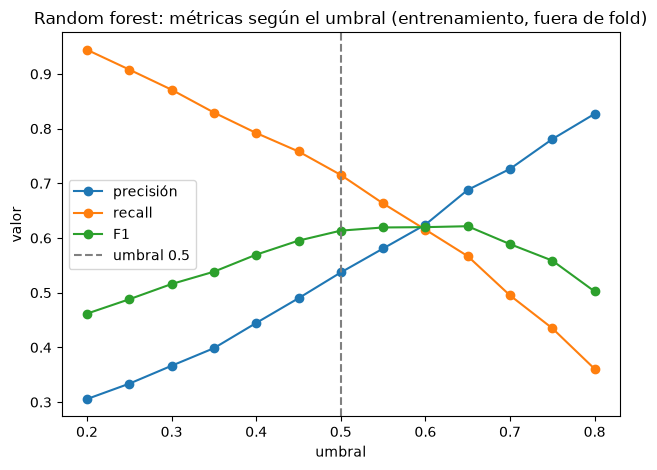

In [47]:
from sklearn.model_selection import cross_val_predict

proba_oof = cross_val_predict(
    busqueda_rf.best_estimator_, X_train, y_train, cv=cv, method='predict_proba', n_jobs=-1
)[:, 1]

umbrales = np.arange(0.20, 0.81, 0.05)
filas = []
for u in umbrales:
    pred = (proba_oof >= u).astype(int)
    filas.append({
        'umbral': u,
        'precision': precision_score(y_train, pred, zero_division=0),
        'recall': recall_score(y_train, pred),
        'f1': f1_score(y_train, pred),
        'contactados_%': pred.mean(),
    })
tabla_umbral = pd.DataFrame(filas)
with pd.option_context('display.float_format', '{:.3f}'.format):
    print(tabla_umbral.to_string(index=False))

mejor = tabla_umbral.loc[tabla_umbral['f1'].idxmax()]
print()
print(f"Umbral con mayor F1 en entrenamiento (fuera de fold): {mejor['umbral']:.2f} (F1 {mejor['f1']:.3f})")

plt.plot(tabla_umbral['umbral'], tabla_umbral['precision'], marker='o', label='precisión')
plt.plot(tabla_umbral['umbral'], tabla_umbral['recall'], marker='o', label='recall')
plt.plot(tabla_umbral['umbral'], tabla_umbral['f1'], marker='o', label='F1')
plt.axvline(0.5, color='gray', linestyle='--', label='umbral 0.5')
plt.xlabel('umbral')
plt.ylabel('valor')
plt.title('Random forest: métricas según el umbral (entrenamiento, fuera de fold)')
plt.legend()
plt.tight_layout()
plt.show()


Con el umbral de 0.5 se contacta al 27% de los clientes. Entre 0.55 y 0.65 el F1 casi no cambia (entre 0.619 y 0.622), pero el porcentaje de clientes contactados baja del 23% al 17% y la precisión sube de 0.58 a 0.69. Es decir que hay varios umbrales con un F1 parecido pero con un número de contactos muy distinto, y la elección entre ellos depende de cuánto cueste cada contacto frente a lo que se gana reteniendo a un cliente. Por esto el umbral se deja en 0.5 en esta sección y se va a escoger en la sección 5, con los costos de la campaña.


## 3.9. Elección del modelo

Se mantiene **random forest** (profundidad máxima 12, mínimo 5 clientes por hoja y 200 árboles) como el modelo elegido, por las siguientes razones:

1. Fue el modelo con el mayor F1 en la validación cruzada, que era el criterio definido antes de mirar el conjunto de prueba.
2. Gradient boosting tuvo resultados un poco mejores en prueba, pero el bootstrapping pareado, la prueba t pareada y la prueba de McNemar mostraron que la diferencia no es significativa, y en F1 tampoco supera el umbral relevante de 0.02. Cambiar de modelo por esa diferencia sería escoger con el conjunto de prueba.
3. Frente a la regresión logística, random forest es significativamente mejor en F1, AUC y precisión, y las diferencias superan el umbral relevante. La logística encuentra 24 abandonos más en prueba, pero contacta a 150 clientes más para lograrlo.
4. En la curva de ganancia, que es la que más importa si el presupuesto de la campaña es limitado, random forest y gradient boosting se comportan casi igual.

Gradient boosting queda como una alternativa equivalente. Si más adelante se tienen más datos, valdría la pena volver a comparar los dos.

Lo que más ayudó a las métricas fue usar modelos que capturan relaciones no lineales, ya que el salto de la regresión logística a los modelos de árboles (y también la mejora de la logística al agregar los términos polinomiales) coincide con lo visto en la sección 1 para la edad y el número de productos. También ayudaron el peso de clases, mantener todas las variables, imputar en lugar de eliminar filas y limitar la profundidad y el tamaño de las hojas para controlar el sobreajuste.


## 3.10. Oportunidades de mejora

- **Escoger el umbral con los costos.** Como se vio en la sección 3.8, con un F1 parecido se puede contactar entre el 17% y el 27% de los clientes. Esto se va a definir en la sección 5.
- **Sobreajuste.** El random forest elegido tiene un F1 de 0.767 en entrenamiento y de 0.613 en validación. Se podría probar con más regularización (por ejemplo limitando `max_features`) o con más datos.
- **Abandonos que no se detectan.** El modelo no encuentra a 121 de los 407 abandonos de prueba. En la sección 4 se va a revisar qué tienen en común estos clientes.
- **Variables de comportamiento.** Cinco modelos muy distintos quedaron con un AUC entre 0.83 y 0.86, lo que sugiere que el límite está más en la información disponible que en el modelo. El dataset solo tiene el perfil del cliente en un momento. Variables como la evolución del saldo, la cantidad de transacciones o las quejas recientes podrían ayudar a detectar mejor el abandono.
- **Tasa de abandono distinta.** La muestra tiene un 20.4% de abandono y el enunciado habla de un 15% para la banca minorista. Con una tasa más baja la precisión del modelo va a ser menor, por lo que habría que validarlo con datos del banco antes de usarlo.
- **Probabilidades.** Como el modelo se entrenó con `class_weight='balanced'`, las probabilidades que entrega están infladas y no se deben leer como la probabilidad real de que un cliente abandone. Si se van a usar para calcular el valor esperado habría que ajustarlas.
- **Grupos pequeños y datos de otra región.** Hay grupos con muy pocos clientes (60 con 4 productos) y la muestra es de clientes europeos, por lo que los resultados pueden no aplicar igual a clientes colombianos.
